# Rentabilidad anual de un alojamiento en Airbnb Bogotá

**Pregunta de investigación 3.** Dadas las características de una vivienda, ¿cuál puede ser su
rentabilidad anual como alojamiento de corta estancia?

**Integrantes:** Esteban, Rubén, Andrés · **Universidad EIA**, Maestría · **Profesor:** Daniel Orozco Restrepo

**Datos.** Inside Airbnb, Bogotá, Distrito Capital, Colombia, compilado el 14 de septiembre de
2026. Licencia Creative Commons Attribution 4.0.

---

El ingreso bruto anual de un alojamiento es la tarifa por noche multiplicada por las noches que
consigue vender, y ninguna de las dos se observa antes de operar.

$$\text{ingreso anual} = \text{tarifa por noche} \times \text{noches ocupadas}$$

Quien formula la pregunta es un propietario que todavía no publicó. Dispone de la vivienda que
tiene y de las decisiones a las que puede comprometerse, y carece de todo historial. El modelo
se construye con esas dos cosas, y los dos factores de la identidad quedan fuera del conjunto
de variables explicativas junto con todo lo que permita reconstruirlos.

---
# Paso 1 — ¿Machine learning?

**Lo primero que revisamos fue si el precio publicado significaba lo mismo en todos los anuncios.**

- Dimos por hecho que la columna de precio era la tarifa de la vivienda, como la de un hotel.
- Al abrir el dato encontramos que no. La fuente no guarda una tarifa fija: guarda el resultado
  de una consulta de disponibilidad, con su fecha y su duración, igual que si uno entrara al
  sitio y pidiera un alojamiento para unas noches concretas.
- De los 18.794 anuncios con precio, 3.052 traen una tarifa mensual repartida entre las noches
  del mes, con los descuentos de estancia larga ya restados. Son un negocio distinto, más
  parecido a un arriendo que a un hospedaje de fin de semana.
- Decidimos analizarlos aparte, porque su precio y su ingreso están medidos de otra manera.

## 1.1 Entorno


In [1]:
import sys                                                   # sys da informacion del interprete en uso
import time                                                  # time mide cuanto tarda cada ajuste
import json                                                  # json lee el objeto de la cotizacion
import numpy as np                                           # numpy: operaciones matematicas y arreglos
import pandas as pd                                          # pandas: manejo de tablas
import matplotlib.pyplot as plt                              # matplotlib: graficos
import sklearn                                               # scikit-learn: modelos y preprocesamiento

import airbnb_comun as ac                                    # modulo del proyecto

ac.estilo()                                                  # fija la paleta y el estilo de las figuras
pd.set_option("display.width", 170)                          # ancho de impresion de las tablas
pd.set_option("display.max_columns", 40)                      # columnas maximas que se imprimen
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # separador de miles y tres decimales

print("Python       ", sys.version.split()[0])
print("scikit-learn ", sklearn.__version__)
print("Semilla      ", ac.SEMILLA)

Python        3.12.10
scikit-learn  1.9.1
Semilla       42


## 1.2 La tarifa publicada y los dos regímenes de precio

La fuente guarda, junto a cada anuncio, la consulta de disponibilidad con que obtuvo la tarifa.
Para los anuncios con estancia mínima larga esa consulta devuelve un precio mensual promedio,
le resta los descuentos de estancia larga y reparte el resultado entre las noches del mes, de
modo que la cifra publicada corresponde a un producto distinto del de una noche suelta.

In [2]:
listings = ac.cargar_listings()                              # carga y abre la cotizacion de cada anuncio
print("Filas y columnas:", listings.shape)

ejemplo = listings.loc[listings["es_mensual"]].index[0]      # un anuncio con tarifa mensual prorrateada
crudo = json.loads(listings.loc[ejemplo, "price_quote_raw"])["quote"]
print()
print("Desglose de la consulta que produjo el precio de un anuncio del regimen mensual:")
for linea in crudo["raw_price_line_items"]:                  # recorre el desglose devuelto
    print(f"   {linea['description']:32s} {linea['price_string']}")
print(f"   {'precio por noche resultante':32s} ${float(crudo['price_per_night']):,.2f}")
print(f"   {'estancia consultada':32s} {crudo['requested_checkin_date']} a {crudo['requested_checkout_date']}")

Filas y columnas: (19505, 96)

Desglose de la consulta que produjo el precio de un anuncio del regimen mensual:
   Average monthly price            $9,431,206.00 COP
   Monthly stay discount            -$922,513.20 COP
   Airbnb monthly stay savings      -$263,769.48 COP
   Price after discount             $8,244,923.32 COP
   precio por noche resultante      $274,830.78
   estancia consultada              2027-04-01 a 2027-04-29


In [3]:
con_tarifa = listings[listings["precio_noche"].notna()]      # anuncios con tarifa publicada
regimen = con_tarifa.groupby("es_mensual").agg(
    anuncios=("id", "size"), tarifa_mediana=("precio_noche", "median"),
    huespedes_mediana=("accommodates", "median"), noches_cotizadas=("noches_cotizadas", "median"),
    ingreso_mediano=("estimated_revenue_l365d", "median"),
)
regimen.index = ["Tarifa por noche", "Tarifa mensual prorrateada"]
print(regimen.to_string())
print()
print(f"El regimen mensual cubre el {con_tarifa['es_mensual'].mean() * 100:.1f} % de los anuncios con tarifa,")
print("con la misma capacidad mediana, tarifa menor e ingreso anual mediano nulo. Su huesped de")
print("estancia larga rara vez deja comentario, de modo que esta mal medido en los dos factores")
print("a la vez y queda fuera del modelo de ingreso.")

                            anuncios  tarifa_mediana  huespedes_mediana  noches_cotizadas  ingreso_mediano
Tarifa por noche               15742     170,000.000              2.000             1.000    4,959,000.000
Tarifa mensual prorrateada      3052      96,900.000              2.000            30.000            0.000

El regimen mensual cubre el 16.2 % de los anuncios con tarifa,
con la misma capacidad mediana, tarifa menor e ingreso anual mediano nulo. Su huesped de
estancia larga rara vez deja comentario, de modo que esta mal medido en los dos factores
a la vez y queda fuera del modelo de ingreso.


In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.6))          # dos paneles

reparto = con_tarifa["es_mensual"].value_counts().rename({False: "Tarifa por noche", True: "Tarifa mensual"})
barras = ejes[0].barh(reparto.index, reparto.values, color=[ac.ACENTO, ac.MORADO], height=0.5)
for barra, valor in zip(barras, reparto.values):             # etiqueta directa en cada barra
    ejes[0].text(valor + reparto.max() * 0.02, barra.get_y() + barra.get_height() / 2,
                 f"{valor:,} ({valor / len(con_tarifa) * 100:.1f} %)", va="center", fontsize=9, color=ac.TINTA)
ejes[0].set_xlim(0, reparto.max() * 1.32)
ejes[0].set_title("Regimen de precio de la cotizacion"); ejes[0].set_xlabel("anuncios")

for etiqueta, color, mascara in [("Tarifa por noche", ac.ACENTO, ~con_tarifa["es_mensual"]),
                                 ("Tarifa mensual", ac.MORADO, con_tarifa["es_mensual"])]:
    ejes[1].hist(np.log1p(con_tarifa.loc[mascara, "precio_noche"]), bins=55, alpha=0.62,
                 color=color, label=etiqueta, edgecolor="white", linewidth=0.3)
ejes[1].set_title("Tarifa por noche segun el regimen")
ejes[1].set_xlabel("log(1 + tarifa por noche)"); ejes[1].set_ylabel("alojamientos")
ejes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

<Figure size 1265x396 with 2 Axes>

## 1.3 El objetivo y su estado de medición

El ingreso que publica la fuente se estima a partir del número de comentarios recibidos. Esa
construcción determina qué significa un cero, y obliga a distinguir tres situaciones antes de
modelar.

In [6]:
datos = ac.preparar_poblacion(listings)                      # agrega exposicion, actividad e ingreso por dia
datos = datos.join(ac.reglas_calendario(), on="id")          # reglas de reserva que el anfitrion fija dia a dia
datos = datos[datos["precio_noche"].notna() & ~datos["es_mensual"]].copy()

print(f"Anuncios en analisis: {len(datos):,}")
print()
print(f"  sin comentario alguno:                  {(~datos['exposicion_observable']).mean() * 100:5.1f} %")
print(f"  sin actividad detectada en la ventana:  {(~datos['actividad_detectada']).mean() * 100:5.1f} %")
print(f"  con exposicion menor a un ano:          {(datos['exposicion_observable'] & ~datos['exposicion_completa']).mean() * 100:5.1f} %")
print(f"  en el techo de la estimacion de noches: {(datos['noches_ocupadas'] >= 255).mean() * 100:5.1f} %")
print()
sin_resena = datos[~datos["exposicion_observable"]]
print(f"De los {len(sin_resena):,} anuncios sin comentario alguno, los que registran ingreso")
print(f"mayor que cero son: {(sin_resena['ingreso_anual'] > 0).sum()}.")
print()
print("El cero no mide el mercado: es el valor que toma la estimacion cuando el metodo no")
print("detecta actividad. Por eso el diseno lo separa en una etapa propia en lugar de")
print("promediarlo con los alojamientos que si venden.")

Anuncios en analisis: 15,742

  sin comentario alguno:                   13.9 %
  sin actividad detectada en la ventana:   25.1 %
  con exposicion menor a un ano:           26.7 %
  en el techo de la estimacion de noches:   6.3 %

De los 2,196 anuncios sin comentario alguno, los que registran ingreso
mayor que cero son: 0.

El cero no mide el mercado: es el valor que toma la estimacion cuando el metodo no
detecta actividad. Por eso el diseno lo separa en una etapa propia en lugar de
promediarlo con los alojamientos que si venden.


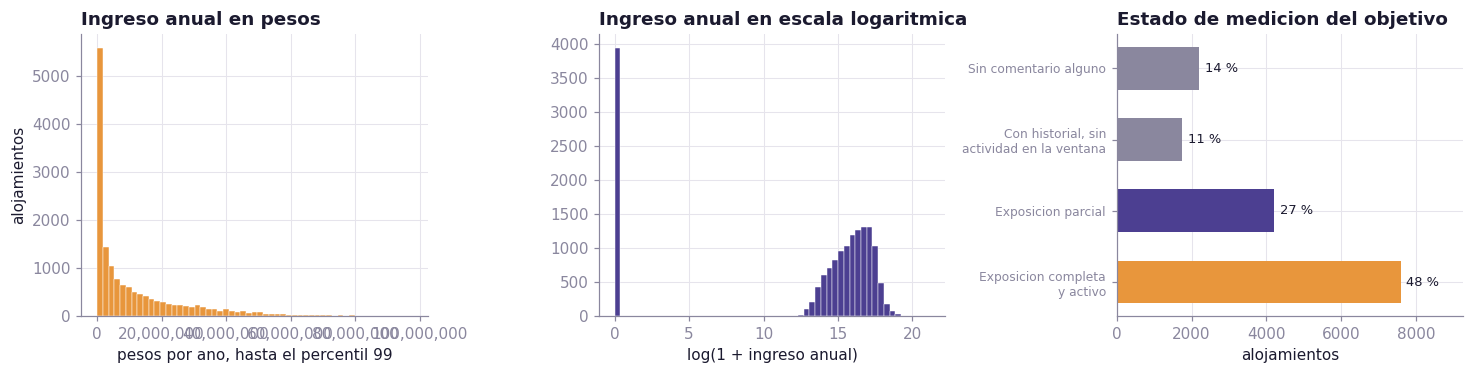

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(13.5, 3.5))          # tres paneles

tope_vista = datos["ingreso_anual"].quantile(0.99)
ejes[0].hist(datos.loc[datos["ingreso_anual"] <= tope_vista, "ingreso_anual"], bins=55,
             color=ac.ACENTO, edgecolor="white", linewidth=0.3)
ejes[0].set_title("Ingreso anual en pesos")
ejes[0].set_xlabel("pesos por ano, hasta el percentil 99"); ejes[0].set_ylabel("alojamientos")
ejes[0].xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))

ejes[1].hist(np.log1p(datos["ingreso_anual"].dropna()), bins=55, color=ac.MORADO,
             edgecolor="white", linewidth=0.3)
ejes[1].set_title("Ingreso anual en escala logaritmica"); ejes[1].set_xlabel("log(1 + ingreso anual)")

composicion = pd.Series({
    "Sin comentario alguno": (~datos["exposicion_observable"]).sum(),
    "Con historial, sin\nactividad en la ventana": (datos["exposicion_observable"] & ~datos["actividad_detectada"]).sum(),
    "Exposicion parcial": (datos["actividad_detectada"] & ~datos["exposicion_completa"]).sum(),
    "Exposicion completa\ny activo": (datos["actividad_detectada"] & datos["exposicion_completa"]).sum(),
})
barras = ejes[2].barh(composicion.index, composicion.values,
                      color=[ac.GRIS, ac.GRIS, ac.MORADO, ac.ACENTO], height=0.6)
for barra, valor in zip(barras, composicion.values):
    ejes[2].text(valor + composicion.max() * 0.02, barra.get_y() + barra.get_height() / 2,
                 f"{valor / len(datos) * 100:.0f} %", va="center", fontsize=8.5, color=ac.TINTA)
ejes[2].set_xlim(0, composicion.max() * 1.22)
ejes[2].invert_yaxis(); ejes[2].tick_params(axis="y", labelsize=8)
ejes[2].set_title("Estado de medicion del objetivo"); ejes[2].set_xlabel("alojamientos")
plt.tight_layout()
plt.show()

## 1.4 Partición de entrenamiento y prueba

Un anfitrión puede publicar decenas de anuncios casi idénticos en el mismo edificio. La
partición agrupa por anfitrión, de modo que todos los anuncios de uno caigan del mismo lado y
el error en prueba corresponda a operadores que el modelo no vio.

In [8]:
from sklearn.model_selection import GroupShuffleSplit         # particion que respeta los grupos

tamanos = datos["host_id"].value_counts()
llave = ["host_id", "room_type", "accommodates", "neighbourhood_cleansed", "precio_noche"]
print(f"Anfitriones distintos: {datos['host_id'].nunique():,}   Maximo de anuncios de uno solo: {tamanos.max()}")
print(f"Anuncios de anfitriones con cinco o mas:    {datos['host_id'].map(tamanos).ge(5).mean() * 100:.1f} %")
print(f"Anuncios con un gemelo del mismo anfitrion: {datos.duplicated(subset=llave, keep=False).mean() * 100:.1f} %")

particion = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=ac.SEMILLA)
indices_train, indices_test = next(particion.split(datos, groups=datos["host_id"]))
train = datos.iloc[indices_train].copy()
test = datos.iloc[indices_test].copy()
print()
print(f"Entrenamiento: {len(train):,} anuncios de {train['host_id'].nunique():,} anfitriones")
print(f"Prueba:        {len(test):,} anuncios de {test['host_id'].nunique():,} anfitriones")
print(f"Anfitriones compartidos entre particiones: {len(set(train['host_id']) & set(test['host_id']))}")

Anfitriones distintos: 5,893   Maximo de anuncios de uno solo: 147
Anuncios de anfitriones con cinco o mas:    53.3 %
Anuncios con un gemelo del mismo anfitrion: 19.7 %

Entrenamiento: 12,863 anuncios de 4,714 anfitriones
Prueba:        2,879 anuncios de 1,179 anfitriones
Anfitriones compartidos entre particiones: 0


## 1.5 Regla a mano

Sin modelo, el propietario dispone del ingreso típico de su localidad. Ese es el error que
cualquier modelo tiene que reducir para justificar su uso.

In [9]:
from sklearn.dummy import DummyRegressor                      # modelo que siempre predice el mismo valor

con_objetivo = train[train["ingreso_anual"].notna()]
prueba_objetivo = test[test["ingreso_anual"].notna()]
regla = ac.ReglaPorGrupo("neighbourhood_cleansed").fit(con_objetivo, con_objetivo["ingreso_anual"])
base = DummyRegressor(strategy="median").fit(con_objetivo, con_objetivo["ingreso_anual"])

referencia = pd.DataFrame({
    "Linea base (mediana de la ciudad)": ac.metricas(prueba_objetivo["ingreso_anual"], base.predict(prueba_objetivo)),
    "Regla a mano (mediana por localidad)": ac.metricas(prueba_objetivo["ingreso_anual"], regla.predict(prueba_objetivo)),
}).T
print(referencia.to_string())
print()
print(f"La regla a mano se equivoca en ${referencia.loc['Regla a mano (mediana por localidad)', 'MedAE']:,.0f} de mediana,")
print(f"sobre un ingreso mediano observado de ${prueba_objetivo['ingreso_anual'].median():,.0f}.")

                                                MAE         MedAE           RMSE     R2
Linea base (mediana de la ciudad)    12,006,860.330 4,998,000.000 34,110,861.187 -0.060
Regla a mano (mediana por localidad) 11,934,555.986 4,890,420.000 34,052,005.805 -0.056

La regla a mano se equivoca en $4,890,420 de mediana,
sobre un ingreso mediano observado de $4,847,800.


---
# Paso 2 — Datos

**La segunda pregunta fue de dónde sacar cuánto se alquiló realmente cada alojamiento.**

- La fuente trae un calendario con las noches libres y ocupadas del año siguiente, así que
  parecía la medida natural de ocupación.
- No lo es, por dos motivos. El calendario mira hacia adelante y la ocupación que necesitamos
  mira hacia atrás, y las reservas se van acumulando a medida que la fecha se acerca, de modo
  que un alojamiento que vendió todo el año pasado aparece con el calendario casi vacío para el
  próximo. Y una noche marcada como no disponible puede estar vendida o puede estar bloqueada
  porque el dueño la usa él mismo, sin que el archivo las distinga.
- La ocupación que sí sirve viene de los comentarios, y lo comprobamos reconstruyéndola desde
  ellos y contrastándola con la que publica la fuente.
- El calendario se queda para dos cosas que sí hace bien: describir cuánto ofrece cada anuncio,
  y aportar las reglas de estancia mínima que el dueño fija día a día.

## 2.1 Fuente y papel de cada tabla

Inside Airbnb publica extracciones periódicas de los anuncios visibles en el sitio. La
extracción corresponde a Bogotá, Distrito Capital, Colombia, compilada el 14 de septiembre de
2026, bajo licencia Creative Commons Attribution 4.0, que permite el uso con atribución.

La tabla de anuncios aporta las variables explicativas y la tarifa. Los comentarios construyen y
verifican la ocupación. El calendario aporta las reglas de reserva que el anfitrión fija día a
día, que son decisiones suyas, y describe el comportamiento de la oferta.

In [9]:
calendario_cols = pd.read_csv(ac.DATOS / "calendar.csv.gz", nrows=0).columns
resenas_cols = pd.read_csv(ac.DATOS / "reviews.csv.gz", nrows=0).columns
print("listings :", f"{listings.shape[0]:,}", "filas  |  una fila por alojamiento")
print("calendar : 7,119,325 filas  |  una fila por alojamiento y dia  |", list(calendario_cols))
print("reviews  :   568,675 filas  |  una fila por comentario         |", list(resenas_cols))
print()
print(f"Anuncios que cambian su estancia minima durante el ano: {datos['varia_estancia_minima'].mean() * 100:.1f} %")

listings : 19,505 filas  |  una fila por alojamiento
calendar : 7,119,325 filas  |  una fila por alojamiento y dia  | ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
reviews  :   568,675 filas  |  una fila por comentario         | ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']

Anuncios que cambian su estancia minima durante el ano: 13.3 %


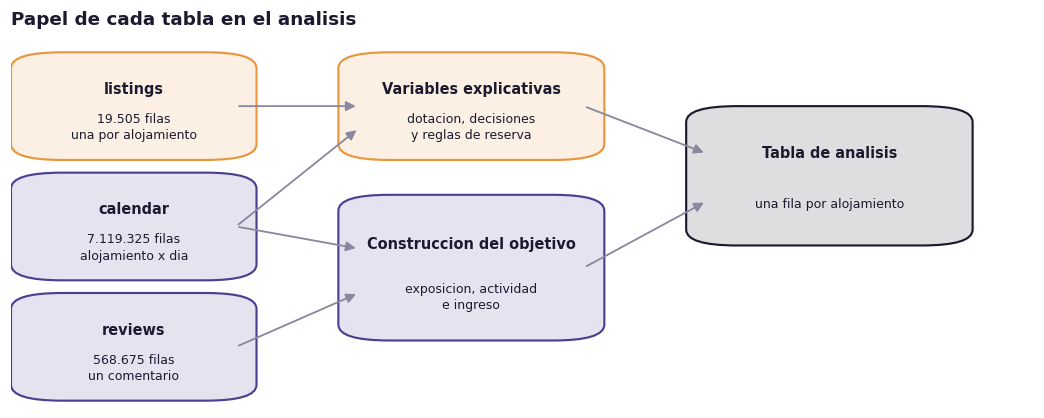

In [10]:
fig, ax = ac.lienzo(12, 4.3)                                  # lienzo para el esquema
ac.caja(ax, 0.02, 0.60, 0.20, 0.30, "listings", "19.505 filas\nuna por alojamiento", ac.ACENTO)
ac.caja(ax, 0.02, 0.22, 0.20, 0.30, "calendar", "7.119.325 filas\nalojamiento x dia", ac.MORADO)
ac.caja(ax, 0.02, -0.16, 0.20, 0.30, "reviews", "568.675 filas\nun comentario", ac.MORADO)
ac.caja(ax, 0.34, 0.60, 0.22, 0.30, "Variables explicativas", "dotacion, decisiones\ny reglas de reserva", ac.ACENTO)
ac.caja(ax, 0.34, 0.03, 0.22, 0.42, "Construccion del objetivo", "exposicion, actividad\ne ingreso", ac.MORADO)
ac.caja(ax, 0.68, 0.33, 0.24, 0.40, "Tabla de analisis", "una fila por alojamiento", ac.TINTA)
ac.flecha(ax, (0.22, 0.75), (0.34, 0.75)); ac.flecha(ax, (0.22, 0.37), (0.34, 0.68))
ac.flecha(ax, (0.22, 0.37), (0.34, 0.30)); ac.flecha(ax, (0.22, -0.01), (0.34, 0.16))
ac.flecha(ax, (0.56, 0.75), (0.68, 0.60)); ac.flecha(ax, (0.56, 0.24), (0.68, 0.45))
ax.set_ylim(-0.2, 0.95)
ax.set_title("Papel de cada tabla en el analisis", loc="left", pad=12)
plt.show()

## 2.2 Verificación del objetivo

El ingreso publicado se verifica por dos vías. La primera divide el ingreso entre las noches
ocupadas y lo compara con la tarifa. La segunda reconstruye la ocupación desde el recuento de
comentarios, que es el procedimiento con que la fuente la estima.

In [11]:
activos_v = train[train["noches_ocupadas"] > 0]
razon = activos_v["ingreso_anual"] / activos_v["noches_ocupadas"]
print(f"El ingreso dividido entre las noches ocupadas reproduce la tarifa publicada")
print(f"en el {np.isclose(razon, activos_v['precio_noche'], rtol=0.001).mean() * 100:.1f} % de los anuncios con actividad.")

t0 = time.time()
fraccion_bloqueada, fecha_corte = ac.ocupacion_calendario()
noches_resenas = ac.ocupacion_reviews(fecha_corte)
verificacion = pd.DataFrame({
    "noches_publicadas": train["noches_ocupadas"],
    "noches_por_resenas": train["id"].map(noches_resenas).fillna(0),
    "fraccion_bloqueada": train["id"].map(fraccion_bloqueada),
})
print()
print(f"Correlacion de rangos entre las tres medidas de ocupacion   ({time.time() - t0:.0f} s de carga):")
print(verificacion.corr(method="spearman").to_string())

El ingreso dividido entre las noches ocupadas reproduce la tarifa publicada
en el 100.0 % de los anuncios con actividad.



Correlacion de rangos entre las tres medidas de ocupacion   (7 s de carga):
                    noches_publicadas  noches_por_resenas  fraccion_bloqueada
noches_publicadas               1.000               0.991               0.189
noches_por_resenas              0.991               1.000               0.177
fraccion_bloqueada              0.189               0.177               1.000


La reconstrucción desde los comentarios reproduce la ocupación publicada, lo que confirma por
qué vía se construye el objetivo y, con ello, qué columnas quedan prohibidas.

El calendario no la verifica. La ocupación estimada mira los trescientos sesenta y cinco días
anteriores a la extracción, mientras que el calendario describe los siguientes, que todavía
nadie reservó. Las reservas se acumulan al acercarse la fecha, de modo que un alojamiento que
vendió el año entero aparece con el calendario casi vacío para el año próximo. A esa confusión
temporal se suma una de significado: una noche no disponible puede estar vendida o bloqueada
porque el anfitrión vive allí, y las dos son indistinguibles en el archivo.

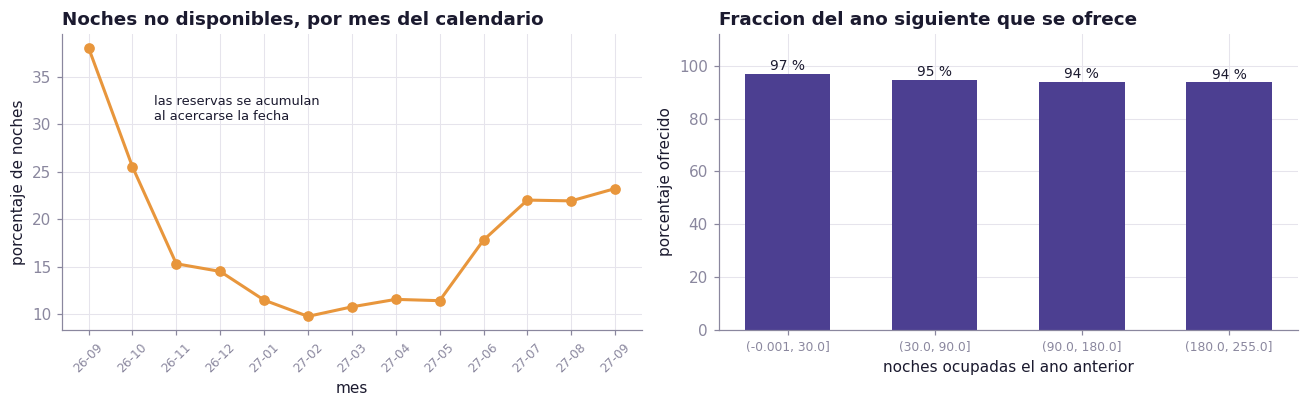

De los anuncios sin ingreso detectado, el 90.7 % ofrece
mas de medio ano de calendario: no es inventario retirado del mercado, sino
alojamientos que se ofrecen y no consiguen venderse.


In [12]:
calendario = pd.read_csv(ac.DATOS / "calendar.csv.gz", usecols=["listing_id", "date", "available"])
calendario["date"] = pd.to_datetime(calendario["date"])
bloqueo = (calendario["available"] == "f").groupby(calendario["date"].dt.to_period("M").astype(str)).mean() * 100
train["fraccion_ofrecida"] = train["id"].map((calendario["available"] == "t").groupby(calendario["listing_id"]).mean())

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].plot(range(len(bloqueo)), bloqueo.values, "o-", color=ac.ACENTO, linewidth=2, markersize=6)
ejes[0].set_xticks(range(len(bloqueo)))
ejes[0].set_xticklabels([m[2:] for m in bloqueo.index], fontsize=8, rotation=45)
ejes[0].set_title("Noches no disponibles, por mes del calendario")
ejes[0].set_xlabel("mes"); ejes[0].set_ylabel("porcentaje de noches")
ejes[0].text(1.5, bloqueo.max() * 0.8, "las reservas se acumulan\nal acercarse la fecha",
             fontsize=8.5, color=ac.TINTA)

tramos = pd.cut(train["noches_ocupadas"], [0, 30, 90, 180, 255], include_lowest=True)
oferta = train.groupby(tramos, observed=True)["fraccion_ofrecida"].median() * 100
barras = ejes[1].bar(range(len(oferta)), oferta.values, color=ac.MORADO, width=0.58)
ejes[1].set_xticks(range(len(oferta))); ejes[1].set_xticklabels([str(i) for i in oferta.index], fontsize=8)
for barra, valor in zip(barras, oferta.values):
    ejes[1].text(barra.get_x() + barra.get_width() / 2, valor + 1.5, f"{valor:.0f} %",
                 ha="center", fontsize=9, color=ac.TINTA)
ejes[1].set_ylim(0, 112)
ejes[1].set_title("Fraccion del ano siguiente que se ofrece")
ejes[1].set_xlabel("noches ocupadas el ano anterior"); ejes[1].set_ylabel("porcentaje ofrecido")
plt.tight_layout()
plt.show()

sin_ingreso = train[train["ingreso_anual"].fillna(0) == 0]
print(f"De los anuncios sin ingreso detectado, el {(sin_ingreso['fraccion_ofrecida'] > 0.5).mean() * 100:.1f} % ofrece")
print("mas de medio ano de calendario: no es inventario retirado del mercado, sino")
print("alojamientos que se ofrecen y no consiguen venderse.")

## 2.3 Auditoría de las columnas

In [13]:
originales = [c for c in listings.columns if c in train.columns]
resumen = pd.DataFrame({
    "tipo": train[originales].dtypes.astype(str),
    "vacios_%": (train[originales].isna().mean() * 100).round(1),
    "unicos": train[originales].nunique(dropna=True),
})
print(f"Columnas revisadas: {len(resumen)}")
print(f"  vacias por completo:        {(resumen['vacios_%'] == 100).sum()}")
print(f"  con un solo valor distinto: {(resumen['unicos'] <= 1).sum()}")
print()
print("Vacias por completo: " + ", ".join(resumen.index[resumen["vacios_%"] == 100]))
print()
print("Auditoria completa guardada en", ac.guardar(resumen, "auditoria_columnas.csv").name)

Columnas revisadas: 96
  vacias por completo:        14
  con un solo valor distinto: 20

Vacias por completo: neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, instant_bookable

Auditoria completa guardada en auditoria_columnas.csv


---
# Paso 3 — Limpieza

**Aquí la pregunta difícil fue qué hacer con los anuncios que aparecen ganando cero.**

- Son más de uno de cada cuatro anuncios, y la tentación era borrarlos por estar mal medidos.
- Antes de borrarlos miramos de dónde sale ese cero. El ingreso se calcula contando comentarios,
  y ningún anuncio sin comentarios aparece con ingreso: ni uno solo. O sea que el cero no dice
  que el alojamiento no se alquiló, dice que el método no detectó que se alquilara.
- En ese grupo conviven tres situaciones distintas. El que nunca se alquiló, el que se alquiló y
  ningún huésped dejó comentario, y el que se publicó hace dos meses y lleva poco tiempo
  ofreciéndose.
- Decidimos conservarlos. Borrarlos dejaría fuera justo a los que no lograron venderse, y el
  resultado quedaría demasiado optimista para alguien que apenas va a empezar.
- Lo que sí corregimos fue el tiempo que cada anuncio lleva publicado, porque comparar lo que
  ganó en un año uno que lleva cinco con uno que lleva dos meses no tiene sentido.

## 3.1 Formato y duplicados


In [14]:
print("Formato original de la tarifa:", listings["price"].dropna().head(3).tolist())
print("Tras la conversion:           ", listings["precio_noche"].dropna().head(3).round(0).tolist())
print()
print(f"Anuncios sin tarifa publicada:            {listings['price'].isna().sum():,}")
print(f"Filas identicas en todas las columnas:    {datos.duplicated().sum()}")
print(f"Identificadores de alojamiento repetidos: {datos['id'].duplicated().sum()}")

Formato original de la tarifa: ['$274,830.78', '$71,692.74', '$137,358.40']
Tras la conversion:            [274831.0, 71693.0, 137358.0]

Anuncios sin tarifa publicada:            711


Filas identicas en todas las columnas:    0
Identificadores de alojamiento repetidos: 0


## 3.2 Valores extremos

La tarifa contiene errores de digitación que producen ingresos imposibles, porque el error se
multiplica por el número de noches. El criterio de Tukey (1977) sitúa el corte en el tercer
cuartil más tres veces el rango intercuartílico, sobre el logaritmo de la tarifa por huésped. La
tarifa por huésped compara alojamientos de tamaño distinto, mientras que un corte sobre la
tarifa total eliminaría viviendas grandes legítimas.

In [15]:
def por_huesped(tabla):                                       # tarifa por huesped de una tabla
    return tabla["precio_noche"] / tabla["accommodates"].clip(lower=1)

log_tarifa = np.log1p(por_huesped(train))
q1, q3 = log_tarifa.quantile([0.25, 0.75])
tope = float(np.expm1(q3 + 3 * (q3 - q1)))
print(f"Tope de Tukey sobre la tarifa por huesped: ${tope:,.0f} por noche")
print(f"Por encima del tope: {(por_huesped(train) > tope).sum()} en entrenamiento y {(por_huesped(test) > tope).sum()} en prueba")
print()
print("Los cinco de mayor tarifa, con el ingreso que implicarian:")
print(train.nlargest(5, "precio_noche")[["precio_noche", "accommodates", "noches_ocupadas", "ingreso_anual"]].to_string())

Tope de Tukey sobre la tarifa por huesped: $618,943 por noche
Por encima del tope: 97 en entrenamiento y 6 en prueba

Los cinco de mayor tarifa, con el ingreso que implicarian:
         precio_noche  accommodates  noches_ocupadas     ingreso_anual
4199  258,514,678.000             2            6.000 1,551,088,068.000
18499 232,260,501.000             2            0.000             0.000
6696  224,768,226.240             1            0.000             0.000
3657  150,025,000.000             3            0.000             0.000
8203   95,000,000.000             4            0.000             0.000


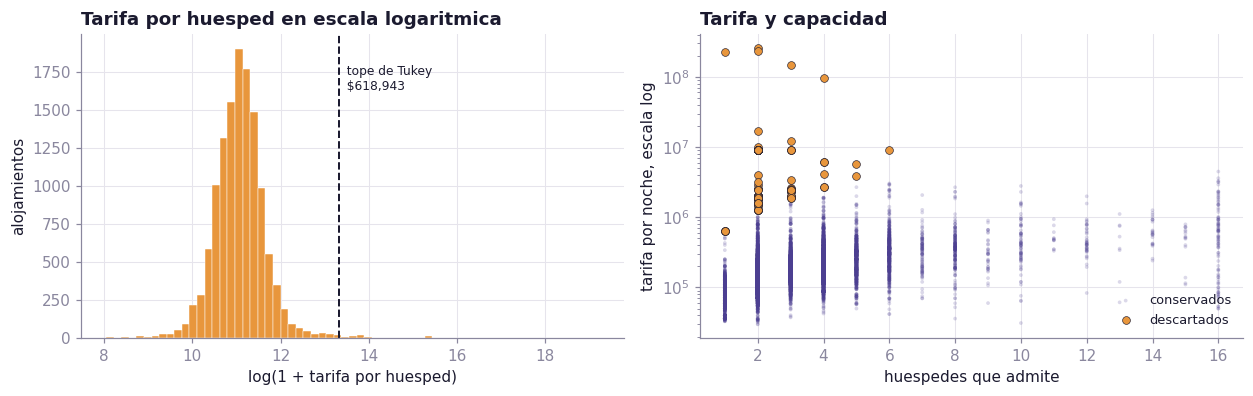

Entrenamiento: 12,766 | Prueba: 2,873


In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.7))
ejes[0].hist(log_tarifa, bins=65, color=ac.ACENTO, edgecolor="white", linewidth=0.3)
ejes[0].axvline(np.log1p(tope), color=ac.TINTA, linewidth=1.3, linestyle="--")
ejes[0].text(np.log1p(tope), ejes[0].get_ylim()[1] * 0.9, f"  tope de Tukey\n  ${tope:,.0f}",
             fontsize=8, color=ac.TINTA, va="top")
ejes[0].set_title("Tarifa por huesped en escala logaritmica")
ejes[0].set_xlabel("log(1 + tarifa por huesped)"); ejes[0].set_ylabel("alojamientos")

conservados = train[por_huesped(train) <= tope]
descartados = train[por_huesped(train) > tope]
ejes[1].scatter(conservados["accommodates"], conservados["precio_noche"], s=6, alpha=0.2,
                color=ac.MORADO, edgecolors="none", label="conservados")
ejes[1].scatter(descartados["accommodates"], descartados["precio_noche"], s=26, color=ac.ACENTO,
                edgecolors=ac.TINTA, linewidth=0.4, label="descartados")
ejes[1].set_yscale("log")
ejes[1].set_title("Tarifa y capacidad")
ejes[1].set_xlabel("huespedes que admite"); ejes[1].set_ylabel("tarifa por noche, escala log")
ejes[1].legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

train = train[por_huesped(train) <= tope].copy()
test = test[por_huesped(test) <= tope].copy()
print(f"Entrenamiento: {len(train):,} | Prueba: {len(test):,}")

## 3.3 Valores faltantes

La estrategia de relleno se decide comparando el error de cada opción. El procedimiento esconde
el veinte por ciento de los valores conocidos, los reconstruye con cada método y mide el error
absoluto medio contra el valor verdadero.

In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

def comparar_relleno(columna, grupo):                         # compara cuatro formas de rellenar
    conocidos = train[train[columna].notna()]
    muestra = conocidos.sample(frac=0.2, random_state=ac.SEMILLA)
    resto = conocidos.drop(muestra.index)
    opciones = {
        "Media": pd.Series(resto[columna].mean(), index=muestra.index),
        "Mediana global": pd.Series(resto[columna].median(), index=muestra.index),
        "Mediana por grupo": muestra[grupo].map(resto.groupby(grupo)[columna].median()).fillna(resto[columna].median()),
    }
    apoyo = ["accommodates", "latitude", "longitude"]
    bosque = RandomForestRegressor(n_estimators=120, random_state=ac.SEMILLA).fit(resto[apoyo], resto[columna])
    opciones["Regresion (bosque)"] = pd.Series(bosque.predict(muestra[apoyo]), index=muestra.index)
    return {n: mean_absolute_error(muestra[columna], v) for n, v in opciones.items()}

relleno = pd.DataFrame({
    "beds (grupo: accommodates)": comparar_relleno("beds", "accommodates"),
    "bedrooms (grupo: accommodates)": comparar_relleno("bedrooms", "accommodates"),
}).T
print(relleno.to_string())
print()
for fila in relleno.index:
    mejor = relleno.loc[fila].idxmin()
    print(f"{fila}: menor error con {mejor.lower()}, MAE {relleno.loc[fila, mejor]:.3f} "
          f"contra {relleno.loc[fila, 'Media']:.3f} de la media")
print()
print("El numero de camas y de habitaciones queda determinado casi por completo por la capacidad")
print("del alojamiento, de modo que condicionar en ella recupera la informacion que la media de")
print("la ciudad ignora. El relleno se aplica dentro del preprocesamiento.")

                                Media  Mediana global  Mediana por grupo  Regresion (bosque)
beds (grupo: accommodates)      0.955           0.939              0.333               0.480
bedrooms (grupo: accommodates)  0.677           0.465              0.308               0.330

beds (grupo: accommodates): menor error con mediana por grupo, MAE 0.333 contra 0.955 de la media
bedrooms (grupo: accommodates): menor error con mediana por grupo, MAE 0.308 contra 0.677 de la media

El numero de camas y de habitaciones queda determinado casi por completo por la capacidad
del alojamiento, de modo que condicionar en ella recupera la informacion que la media de
la ciudad ignora. El relleno se aplica dentro del preprocesamiento.


## 3.4 Exposición

El ingreso publicado agrega trescientos sesenta y cinco días, y no todos los anuncios estuvieron
publicados ese tiempo. El objetivo se expresa como tasa por día expuesto, lo que restituye la
comparabilidad sin eliminar observaciones. La exposición solo es observable para los anuncios
con al menos un comentario, porque el archivo no trae la fecha de publicación.

Exposicion observable: 10,962 de 12,766 anuncios
Exposicion mediana: 365 dias   Con menos de un ano: 31.4 %

Ingreso por dia expuesto, entre los anuncios con actividad detectada:
count       9,586.000
mean       67,533.854
std        98,374.088
min           705.737
25%        15,096.194
50%        40,844.712
75%        87,749.314
95%       205,241.408
max     2,563,800.000


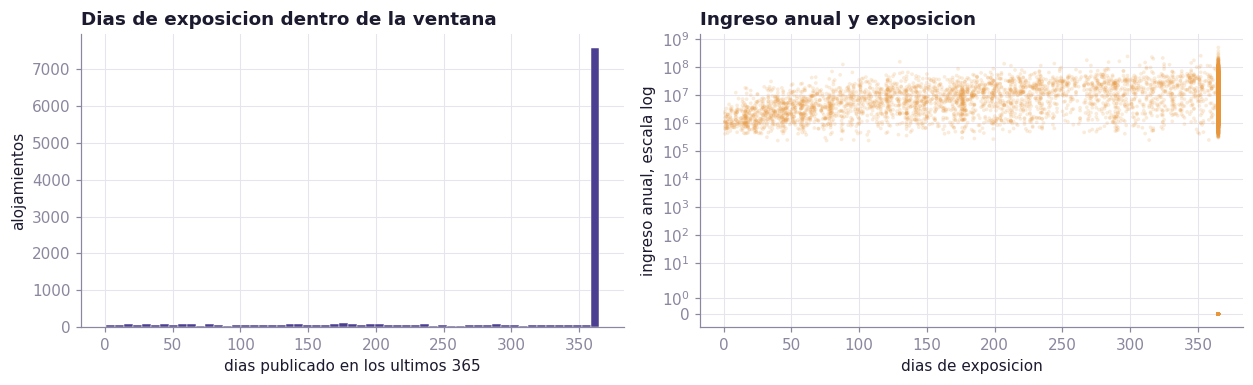

In [18]:
observable = train[train["exposicion_observable"]]
activos_obs = observable[observable["actividad_detectada"]]
print(f"Exposicion observable: {len(observable):,} de {len(train):,} anuncios")
print(f"Exposicion mediana: {observable['dias_expuesto'].median():.0f} dias   "
      f"Con menos de un ano: {(~observable['exposicion_completa']).mean() * 100:.1f} %")
print()
print("Ingreso por dia expuesto, entre los anuncios con actividad detectada:")
print(activos_obs["ingreso_por_dia"].describe(percentiles=[.25, .5, .75, .95]).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.6))
ejes[0].hist(observable["dias_expuesto"], bins=55, color=ac.MORADO, edgecolor="white", linewidth=0.3)
ejes[0].set_title("Dias de exposicion dentro de la ventana")
ejes[0].set_xlabel("dias publicado en los ultimos 365"); ejes[0].set_ylabel("alojamientos")
ejes[1].scatter(observable["dias_expuesto"], observable["ingreso_anual"], s=6, alpha=0.18,
                color=ac.ACENTO, edgecolors="none")
ejes[1].set_yscale("symlog")
ejes[1].set_title("Ingreso anual y exposicion")
ejes[1].set_xlabel("dias de exposicion"); ejes[1].set_ylabel("ingreso anual, escala log")
plt.tight_layout()
plt.show()

## 3.5 Fugas

Una fuga es una columna que solo se conoce después del resultado, o que se calcula con él. La
tarifa y las noches ocupadas son los dos factores del producto. La ocupación se deriva del
recuento de comentarios, de modo que toda columna de comentarios y de calificaciones reconstruye
el objetivo por una vía indirecta. La disponibilidad describe el calendario ya operado, y la
fecha de la cotización mide cuánto lleva cerrado el calendario, porque la consulta pidió la
primera fecha con disponibilidad.

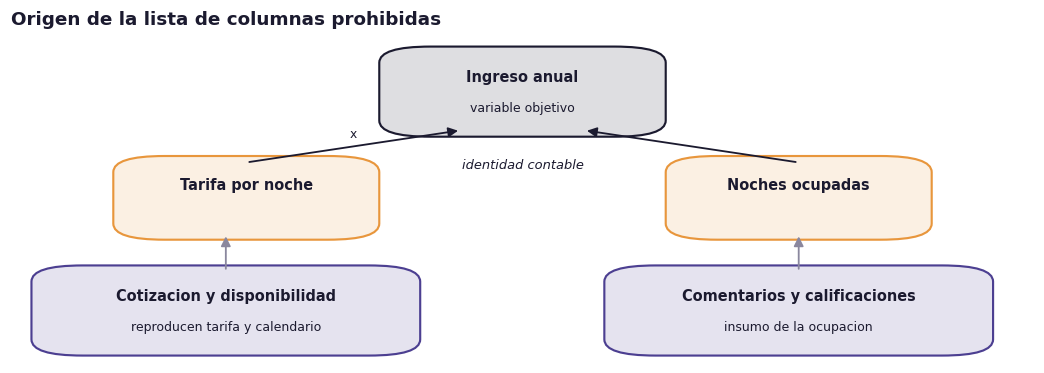

Grupo
Fuga               29
Vacias             14
Redundantes        12
Identificadores     9
Constantes          4
Sin_tratamiento     3

Total de columnas fuera del modelo: 71
Tabla completa guardada en columnas_descartadas.csv


In [19]:
fig, ax = ac.lienzo(12, 3.8)
ac.caja(ax, 0.38, 0.72, 0.24, 0.24, "Ingreso anual", "variable objetivo", ac.TINTA)
ac.caja(ax, 0.12, 0.40, 0.22, 0.22, "Tarifa por noche", "", ac.ACENTO)
ac.caja(ax, 0.66, 0.40, 0.22, 0.22, "Noches ocupadas", "", ac.ACENTO)
ac.caja(ax, 0.60, 0.04, 0.34, 0.24, "Comentarios y calificaciones", "insumo de la ocupacion", ac.MORADO)
ac.caja(ax, 0.04, 0.04, 0.34, 0.24, "Cotizacion y disponibilidad", "reproducen tarifa y calendario", ac.MORADO)
ac.flecha(ax, (0.23, 0.62), (0.44, 0.72), "x", ac.TINTA)
ac.flecha(ax, (0.77, 0.62), (0.56, 0.72), "", ac.TINTA)
ac.flecha(ax, (0.77, 0.28), (0.77, 0.40)); ac.flecha(ax, (0.21, 0.28), (0.21, 0.40))
ax.text(0.5, 0.60, "identidad contable", ha="center", fontsize=8.5, color=ac.TINTA, style="italic")
ax.set_title("Origen de la lista de columnas prohibidas", loc="left", pad=10)
plt.show()

descartes = ac.tabla_descartes()
print(descartes["Grupo"].value_counts().to_string())
print()
print(f"Total de columnas fuera del modelo: {len(descartes)}")
print("Tabla completa guardada en", ac.guardar(descartes, "columnas_descartadas.csv").name)

---
# Paso 4 — Columnas

**Nos preguntamos qué columnas había que dejar fuera, y encontramos que hay dos razones
distintas para sacar una columna.**

- **Por contenido**, cuando la columna no trae datos. De las 90 columnas que trae el archivo, 14
  llegan completamente vacías y otras 6 repiten siempre el mismo valor. El caso más llamativo es la columna de
  baños, que está vacía en los 19.505 anuncios; el número de baños tocó sacarlo del texto que
  los describe, donde dice cosas como un baño privado o baño compartido.
- **Por concepto**, cuando la columna ya contiene la respuesta. El ingreso es el precio
  multiplicado por las noches vendidas, así que el precio, la disponibilidad, los comentarios y
  las calificaciones no pueden usarse para predecirlo: sería adivinar con el resultado a la
  vista. Son 29 columnas.

**Después probamos tres grupos de variables nuevas, y los tres quedaron fuera.**

- El texto del anuncio convertido en números no mejora nada, y el modelo empeora.
- El precio típico de los veinticinco alojamientos más cercanos tampoco aporta, porque las
  coordenadas y las distancias al centro ya traían esa información.
- La fecha de la consulta sí mejora, pero hace trampa: esa fecha es la primera con
  disponibilidad, así que indica cuánto lleva el calendario cerrado, que es parte del resultado.

**Y para que el modelo no se volviera inmanejable, recortamos las comodidades.**

- Las comodidades son los elementos extra que puede tener un alojamiento, como cafetera,
  ascensor, parqueadero o escritorio. En el archivo hay 3.707 distintas.
- Nos quedamos con las que aparecen en al menos uno de cada diez anuncios, y quedaron 68. Las
  que tienen casi todos no sirven para distinguir, y las que casi nadie tiene aparecen tan pocas
  veces que el modelo no alcanza a aprender nada de ellas.

## 4.1 Selección por mecanismo y por quién controla cada variable

La selección declara el mecanismo por el que se espera que cada variable afecte al ingreso, y el
signo de ese efecto, antes de medir cualquier asociación. Una selección guiada por la asociación
observada sobre los mismos datos con que después se entrena infla el desempeño aparente y
descarta efectos no monótonos.

La pregunta la formula un propietario que todavía no publicó, lo que parte las variables en tres
grupos. La dotación es lo que ya posee y no elige. Las decisiones son aquello a lo que puede
comprometerse antes de publicar, desde arrendar una habitación o la vivienda entera hasta la
estancia mínima que exigirá o las comodidades que instalará. El desempeño es consecuencia de
haber operado y no existe para él, de modo que queda fuera: toma siempre el mismo valor en todas
las predicciones que este propietario va a pedir.

In [20]:
variables = ac.tabla_variables()
print(f"Variables declaradas: {len(variables)} en {variables['Tema'].nunique()} temas")
print()
print(pd.crosstab(variables["Tema"], variables["Quien la controla"]).to_string())
print()
for grupo in ["Dotacion", "Decision", "Desempeno"]:
    bloque = variables[variables["Quien la controla"] == grupo]
    print(f"{grupo} ({len(bloque)}): " + ", ".join(bloque["Variable"]))
print()
print("Bloques del modelo: " + ", ".join(ac.BLOQUES_ELEGIDOS))
print("Tabla guardada en", ac.guardar(variables, "variables_seleccionadas.csv").name)

Variables declaradas: 31 en 7 temas

Quien la controla  Decision  Desempeno  Dotacion
Tema                                            
Anfitrion                 3          2         0
Equipamiento              2          0         0
Estructura                2          0         8
Presentacion              3          0         0
Reglas de reserva         3          0         0
Tipologia                 1          0         1
Ubicacion                 0          0         6

Dotacion (15): bedrooms, beds, n_banos, bano_compartido, huesp_x_habitacion, camas_x_habitacion, banos_x_huesped, latitude, longitude, dist_zona_t, dist_aeropuerto, dist_centro_hist, neighbourhood_cleansed, metros_cuadrados, property_type
Decision (14): accommodates, n_amenities, am_* (dummies), log_min_noches, estadia_min_larga, log_max_noches, log_anuncios_host, anuncios_completos, tiene_licencia, largo_nombre, largo_descripcion, t_* (palabras del titulo), declara_area, room_type
Desempeno (2): antiguedad_host, es

## 4.2 Señal medida

La correlación de rangos de Spearman recoge la asociación monótona, mientras que la información
mutua recoge cualquier dependencia, incluida la que cambia de signo a lo largo del recorrido de
la variable. La información mutua estimada por vecinos crece con el número de valores distintos,
de modo que sirve como tamiz y la confirmación llega con la importancia por permutación sobre el
modelo ya ajustado.

In [21]:
from sklearn.feature_selection import mutual_info_regression

preparado = ac.CrearColumnas().fit_transform(train)
preparado = ac.DummiesAmenities().fit(preparado).transform(preparado)
numericas = []
for nombre in ac.BLOQUES_ELEGIDOS:
    numericas += ac.BLOQUES.get(nombre, [])
numericas = [c for c in dict.fromkeys(numericas) if c in preparado.columns]

medible = preparado[preparado["ingreso_anual"].notna()]
objetivo = np.log1p(medible["ingreso_anual"])
matriz = medible[numericas].apply(lambda s: s.fillna(s.median()))
senal = pd.DataFrame({
    "rho_Spearman": [medible[c].corr(objetivo, method="spearman") for c in numericas],
    "info_mutua": mutual_info_regression(matriz, objetivo, random_state=ac.SEMILLA),
}, index=numericas).sort_values("info_mutua", ascending=False)

caso = (senal["info_mutua"].rank(ascending=False) - senal["rho_Spearman"].abs().rank(ascending=False)).idxmin()
print(f"Variables numericas medidas: {len(senal)}")
print()
print(senal.head(14).round(4).to_string())
print()
print(f"La variable {caso} ilustra la diferencia entre los dos criterios: correlacion de rangos")
print(f"{senal.loc[caso, 'rho_Spearman']:.3f}, que un filtro lineal descartaria, con informacion mutua {senal.loc[caso, 'info_mutua']:.3f}.")

Variables numericas medidas: 33

                    rho_Spearman  info_mutua
anuncios_completos         0.176       0.152
log_anuncios_host         -0.013       0.130
n_amenities                0.410       0.117
latitude                   0.017       0.110
dist_centro_hist           0.007       0.099
dist_aeropuerto           -0.007       0.094
longitude                  0.062       0.093
dist_zona_t               -0.100       0.090
accommodates               0.203       0.068
largo_descripcion          0.207       0.065
banos_x_huesped           -0.185       0.061
n_banos                    0.034       0.050
huesp_x_habitacion         0.153       0.044
log_max_noches             0.172       0.043

La variable log_anuncios_host ilustra la diferencia entre los dos criterios: correlacion de rangos
-0.013, que un filtro lineal descartaria, con informacion mutua 0.130.


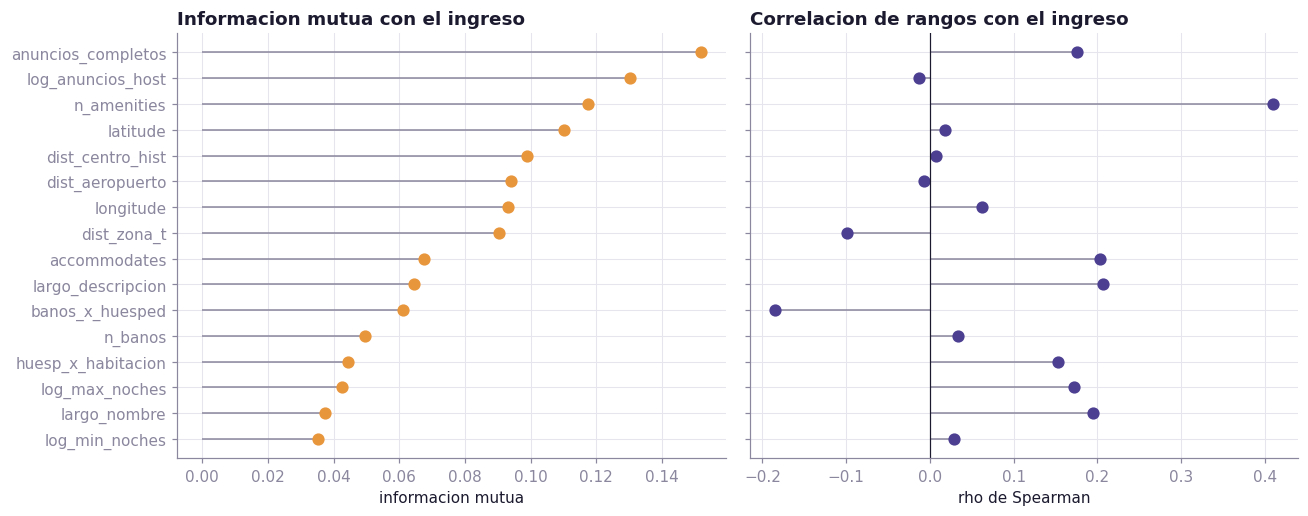

In [22]:
top = senal.head(16).iloc[::-1]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
ejes[0].hlines(top.index, 0, top["info_mutua"], color=ac.GRIS, linewidth=1)
ejes[0].plot(top["info_mutua"], top.index, "o", color=ac.ACENTO, markersize=7)
ejes[0].set_title("Informacion mutua con el ingreso"); ejes[0].set_xlabel("informacion mutua")
ejes[1].hlines(top.index, 0, top["rho_Spearman"], color=ac.GRIS, linewidth=1)
ejes[1].plot(top["rho_Spearman"], top.index, "o", color=ac.MORADO, markersize=7)
ejes[1].axvline(0, color=ac.TINTA, linewidth=0.8)
ejes[1].set_title("Correlacion de rangos con el ingreso"); ejes[1].set_xlabel("rho de Spearman")
plt.tight_layout()
plt.show()

## 4.3 Preprocesamiento

El preprocesamiento es un objeto único que la validación cruzada reajusta en cada partición, de
modo que ninguna mediana ni ninguna lista de comodidades aprendida con todos los datos viaje a
la partición de validación. Las comodidades que reciben columna propia son las presentes en al
menos uno de cada diez anuncios. Las muy raras no cambian el error y ensanchan la matriz, y las
casi universales no distinguen a un alojamiento de otro.

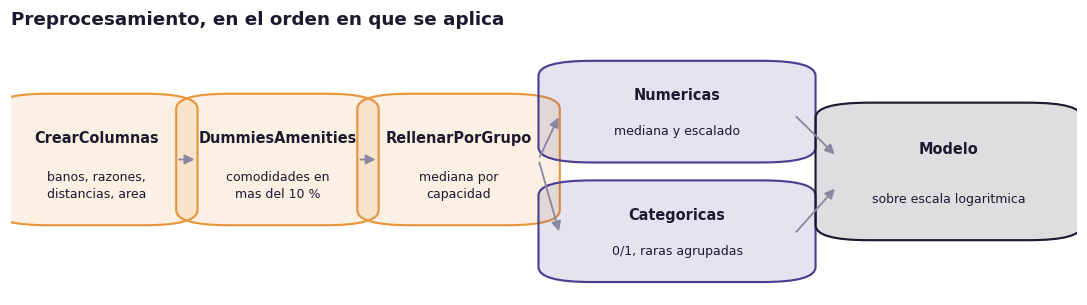

Matriz: 12,766 filas x 126 columnas
  numericas:   33
  comodidades: 68
  categorias:  25
Vacios que quedan: 0

Las 31 variables declaradas se expanden a 126 columnas por dos vias: tres
variables de texto se abren en una columna por categoria, y la lista de comodidades se
abre en una columna de presencia por comodidad frecuente.


In [23]:
fig, ax = ac.lienzo(12.5, 3.0)
ac.caja(ax, 0.005, 0.35, 0.15, 0.40, "CrearColumnas", "banos, razones,\ndistancias, area", ac.ACENTO)
ac.caja(ax, 0.175, 0.35, 0.15, 0.40, "DummiesAmenities", "comodidades en\nmas del 10 %", ac.ACENTO)
ac.caja(ax, 0.345, 0.35, 0.15, 0.40, "RellenarPorGrupo", "mediana por\ncapacidad", ac.ACENTO)
ac.caja(ax, 0.515, 0.56, 0.22, 0.30, "Numericas", "mediana y escalado", ac.MORADO)
ac.caja(ax, 0.515, 0.16, 0.22, 0.30, "Categoricas", "0/1, raras agrupadas", ac.MORADO)
ac.caja(ax, 0.775, 0.30, 0.21, 0.42, "Modelo", "sobre escala logaritmica", ac.TINTA)
ac.flecha(ax, (0.155, 0.55), (0.175, 0.55)); ac.flecha(ax, (0.325, 0.55), (0.345, 0.55))
ac.flecha(ax, (0.495, 0.55), (0.515, 0.70)); ac.flecha(ax, (0.495, 0.55), (0.515, 0.30))
ac.flecha(ax, (0.735, 0.70), (0.775, 0.56)); ac.flecha(ax, (0.735, 0.30), (0.775, 0.46))
ax.set_ylim(0.1, 0.95)
ax.set_title("Preprocesamiento, en el orden en que se aplica", loc="left", pad=10)
plt.show()

preprocesador = ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)
matriz_train = preprocesador.fit_transform(train, np.log1p(train["ingreso_anual"].fillna(0)))
nombres = list(preprocesador.named_steps["columnas"].get_feature_names_out())
print(f"Matriz: {matriz_train.shape[0]:,} filas x {matriz_train.shape[1]} columnas")
print(f"  numericas:   {sum(1 for n in nombres if n.startswith('num__'))}")
print(f"  comodidades: {sum(1 for n in nombres if n.startswith('am__'))}")
print(f"  categorias:  {sum(1 for n in nombres if n.startswith('cat__'))}")
print(f"Vacios que quedan: {int(np.isnan(matriz_train).sum())}")
print()
print(f"Las {len(variables)} variables declaradas se expanden a {matriz_train.shape[1]} columnas por dos vias: tres")
print("variables de texto se abren en una columna por categoria, y la lista de comodidades se")
print("abre en una columna de presencia por comodidad frecuente.")

## 4.4 Aporte de cada bloque

La ablación añade los bloques de uno en uno y mide el error con la misma validación cruzada
agrupada, de modo que conservar un bloque descanse en la diferencia de error y no en el criterio
con que se propuso. La comparación se hace sobre el objetivo en escala logarítmica, porque en
pesos el error cuadrático queda dominado por la cola derecha.

In [24]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline

cv = GroupKFold(n_splits=5)
medible_train = train[train["ingreso_anual"].notna()].copy()
grupos = medible_train["host_id"]
objetivo_log = np.log1p(medible_train["ingreso_anual"])

CONFIGURACIONES = [
    ("1. Estructura y tipologia", ["estructura", "tipologia"]),
    ("2. + Ubicacion", ["estructura", "tipologia", "ubicacion"]),
    ("3. + Reglas de reserva", ["estructura", "tipologia", "ubicacion", "reglas", "reglas_calendario"]),
    ("4. + Decisiones del anfitrion", ["estructura", "tipologia", "ubicacion", "reglas",
                                        "reglas_calendario", "decision_anfitrion"]),
    ("5. + Comodidades", ["estructura", "tipologia", "ubicacion", "reglas", "reglas_calendario",
                           "decision_anfitrion", "equipamiento", "comodidades"]),
    ("6. + Presentacion y area", ac.BLOQUES_ELEGIDOS),
]
filas = []
for nombre, bloques in CONFIGURACIONES:
    pipe = Pipeline([("prep", ac.armar_preprocesador(bloques)),
                     ("modelo", HistGradientBoostingRegressor(random_state=ac.SEMILLA))])
    r = cross_validate(pipe, medible_train, objetivo_log, cv=cv, groups=grupos,
                       scoring="r2", return_train_score=True)
    filas.append({"Configuracion": nombre,
                  "Columnas": ac.armar_preprocesador(bloques).fit_transform(medible_train, objetivo_log).shape[1],
                  "R2 validacion": r["test_score"].mean(), "desv": r["test_score"].std(),
                  "R2 entrenamiento": r["train_score"].mean()})
    print(f"  {nombre:32s} {filas[-1]['Columnas']:4d} columnas   R2 {filas[-1]['R2 validacion']:.4f}", flush=True)

ablacion = pd.DataFrame(filas).set_index("Configuracion")
ablacion["Ganancia"] = ablacion["R2 validacion"].diff()
ablacion["Brecha"] = ablacion["R2 entrenamiento"] - ablacion["R2 validacion"]
print()
print(ablacion.round(4).to_string())
ac.guardar(ablacion, "ablacion_ingreso.csv")

  1. Estructura y tipologia          33 columnas   R2 0.0737


  2. + Ubicacion                     38 columnas   R2 0.0831


  3. + Reglas de reserva             45 columnas   R2 0.1070


  4. + Decisiones del anfitrion      48 columnas   R2 0.1121


  5. + Comodidades                  117 columnas   R2 0.2296


  6. + Presentacion y area          126 columnas   R2 0.2323



                               Columnas  R2 validacion  desv  R2 entrenamiento  Ganancia  Brecha
Configuracion                                                                                   
1. Estructura y tipologia            33          0.074 0.037             0.194       NaN   0.120
2. + Ubicacion                       38          0.083 0.026             0.347     0.009   0.264
3. + Reglas de reserva               45          0.107 0.028             0.391     0.024   0.284
4. + Decisiones del anfitrion        48          0.112 0.034             0.440     0.005   0.328
5. + Comodidades                    117          0.230 0.025             0.520     0.117   0.291
6. + Presentacion y area            126          0.232 0.024             0.533     0.003   0.300


WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/ablacion_ingreso.csv')

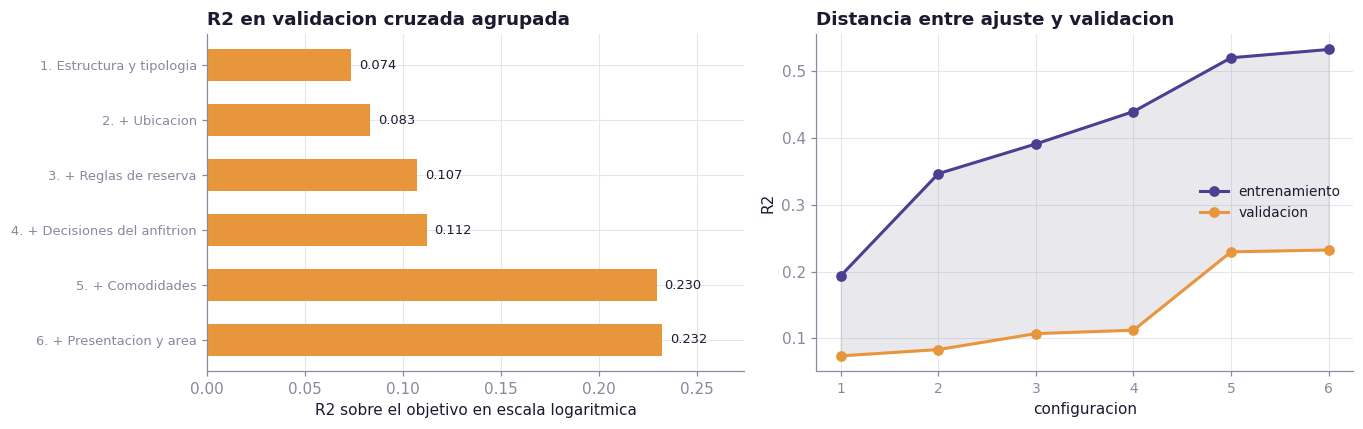

Aporte de cada bloque:
Configuracion
5. + Comodidades                0.117
3. + Reglas de reserva          0.024
2. + Ubicacion                  0.009
4. + Decisiones del anfitrion   0.005
6. + Presentacion y area        0.003

Brecha entre ajuste y validacion en la configuracion final: 0.3005


In [25]:
fig, ejes = plt.subplots(1, 2, figsize=(12.5, 4))
posicion = np.arange(len(ablacion))
ejes[0].barh(posicion, ablacion["R2 validacion"], color=ac.ACENTO, height=0.58)
ejes[0].set_yticks(posicion); ejes[0].set_yticklabels(ablacion.index, fontsize=8.5)
ejes[0].invert_yaxis()
for i, valor in enumerate(ablacion["R2 validacion"]):
    ejes[0].text(valor + 0.004, i, f"{valor:.3f}", va="center", fontsize=8.5, color=ac.TINTA)
ejes[0].set_xlim(0, ablacion["R2 validacion"].max() * 1.18)
ejes[0].set_title("R2 en validacion cruzada agrupada")
ejes[0].set_xlabel("R2 sobre el objetivo en escala logaritmica")

ejes[1].plot(posicion, ablacion["R2 entrenamiento"], "o-", color=ac.MORADO, linewidth=2, markersize=6, label="entrenamiento")
ejes[1].plot(posicion, ablacion["R2 validacion"], "o-", color=ac.ACENTO, linewidth=2, markersize=6, label="validacion")
ejes[1].fill_between(posicion, ablacion["R2 validacion"], ablacion["R2 entrenamiento"], color=ac.GRIS, alpha=0.18)
ejes[1].set_xticks(posicion); ejes[1].set_xticklabels([n.split(".")[0] for n in ablacion.index], fontsize=9)
ejes[1].set_title("Distancia entre ajuste y validacion")
ejes[1].set_xlabel("configuracion"); ejes[1].set_ylabel("R2")
ejes[1].legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

print("Aporte de cada bloque:")
print(ablacion["Ganancia"].dropna().sort_values(ascending=False).round(4).to_string())
print()
print(f"Brecha entre ajuste y validacion en la configuracion final: {ablacion.iloc[-1]['Brecha']:.4f}")

## 4.5 Cuántas comodidades conviene abrir

In [26]:
UMBRALES = [0.03, 0.10, 0.20, 0.35]
filas_p = []
for umbral in UMBRALES:
    pipe = Pipeline([("prep", ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)),
                     ("modelo", HistGradientBoostingRegressor(random_state=ac.SEMILLA))])
    pipe.set_params(prep__dummies__frec_min=umbral)
    r = cross_validate(pipe, medible_train, objetivo_log, cv=cv, groups=grupos, scoring="r2")
    prep = ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS); prep.set_params(dummies__frec_min=umbral)
    m = prep.fit_transform(medible_train, objetivo_log)
    filas_p.append({"Umbral": f"{umbral * 100:.0f} %", "Comodidades": len(prep.named_steps["dummies"].nombres_),
                    "Columnas": m.shape[1], "R2 validacion": r["test_score"].mean()})
    print(f"  presentes en mas del {umbral * 100:4.0f} %   {filas_p[-1]['Comodidades']:3d} comodidades   "
          f"{filas_p[-1]['Columnas']:3d} columnas   R2 {filas_p[-1]['R2 validacion']:.4f}", flush=True)

sin_com = [b for b in ac.BLOQUES_ELEGIDOS if b != "comodidades"]
r = cross_validate(Pipeline([("prep", ac.armar_preprocesador(sin_com)),
                             ("modelo", HistGradientBoostingRegressor(random_state=ac.SEMILLA))]),
                   medible_train, objetivo_log, cv=cv, groups=grupos, scoring="r2")
m = ac.armar_preprocesador(sin_com).fit_transform(medible_train, objetivo_log)
filas_p.append({"Umbral": "ninguna", "Comodidades": 0, "Columnas": m.shape[1],
                "R2 validacion": r["test_score"].mean()})
parsimonia = pd.DataFrame(filas_p).set_index("Umbral")
print()
print(parsimonia.round(4).to_string())
print()
print(f"Pasar del 3 % al 10 % reduce la matriz en {int(parsimonia.loc['3 %', 'Columnas'] - parsimonia.loc['10 %', 'Columnas'])} columnas y cuesta "
      f"{parsimonia.loc['3 %', 'R2 validacion'] - parsimonia.loc['10 %', 'R2 validacion']:.4f} de R2.")
print(f"Prescindir de las comodidades cuesta {parsimonia.loc['10 %', 'R2 validacion'] - parsimonia.loc['ninguna', 'R2 validacion']:.4f}, que ya no es despreciable.")
ac.guardar(parsimonia, "parsimonia_comodidades.csv")

  presentes en mas del    3 %   101 comodidades   159 columnas   R2 0.2367


  presentes en mas del   10 %    68 comodidades   126 columnas   R2 0.2323


  presentes en mas del   20 %    44 comodidades   102 columnas   R2 0.2250


  presentes en mas del   35 %    31 comodidades    89 columnas   R2 0.2178



         Comodidades  Columnas  R2 validacion
Umbral                                       
3 %              101       159          0.237
10 %              68       126          0.232
20 %              44       102          0.225
35 %              31        89          0.218
ninguna            0        58          0.181

Pasar del 3 % al 10 % reduce la matriz en 33 columnas y cuesta 0.0044 de R2.
Prescindir de las comodidades cuesta 0.0510, que ya no es despreciable.


WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/parsimonia_comodidades.csv')

---
# Paso 5 — Modelos

**La pregunta de este paso fue si un solo modelo podía con todo.**

- No puede, por el grupo de los que ganan cero. Un modelo único reparte la diferencia y termina
  prediciendo cantidades intermedias para todos, demasiado altas para los que no venden y
  demasiado bajas para los que sí.
- Lo partimos en dos preguntas más simples. Primero, si el alojamiento llega a alquilarse.
  Después, cuánto rinde si se alquila. El resultado final es el producto de las dos.
- También probamos un modelo distinto para cada tipo de alojamiento, apartamento entero por un
  lado y habitación por otro. Empeoró, porque al partir la muestra cada modelo se queda con
  menos datos para aprender, y el tipo de alojamiento ya entraba como una variable más.

## 5.1 El diseño en dos etapas

Una regresión única sobre un objetivo con un tercio de ceros reparte la diferencia y asigna
valores intermedios a alojamientos que no registran ninguna venta. El diseño separa las dos
preguntas que el propietario tiene mezcladas y las vuelve a unir al final.

La primera etapa estima con qué probabilidad el alojamiento llega a registrar actividad
detectable. La etiqueta es la detección y no la venta, porque el método reconoce la actividad a
través de los comentarios. La segunda estima cuánto rinde por día de exposición un alojamiento
que sí la registra. El producto, extendido a un año, es la cifra comparable con un arriendo.

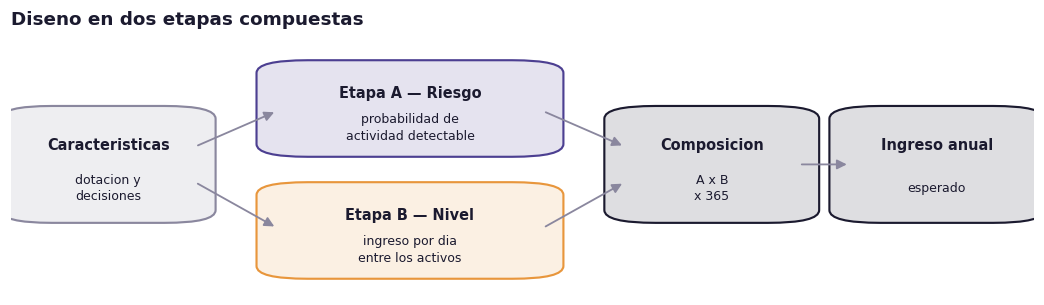

In [27]:
fig, ax = ac.lienzo(12, 3.0)
ac.caja(ax, 0.01, 0.30, 0.17, 0.42, "Caracteristicas", "dotacion y\ndecisiones", ac.GRIS)
ac.caja(ax, 0.26, 0.56, 0.26, 0.34, "Etapa A — Riesgo", "probabilidad de\nactividad detectable", ac.MORADO)
ac.caja(ax, 0.26, 0.08, 0.26, 0.34, "Etapa B — Nivel", "ingreso por dia\nentre los activos", ac.ACENTO)
ac.caja(ax, 0.60, 0.30, 0.17, 0.42, "Composicion", "A x B\nx 365", ac.TINTA)
ac.caja(ax, 0.82, 0.30, 0.17, 0.42, "Ingreso anual", "esperado", ac.TINTA)
ac.flecha(ax, (0.18, 0.58), (0.26, 0.72)); ac.flecha(ax, (0.18, 0.44), (0.26, 0.26))
ac.flecha(ax, (0.52, 0.72), (0.60, 0.58)); ac.flecha(ax, (0.52, 0.26), (0.60, 0.44))
ac.flecha(ax, (0.77, 0.51), (0.82, 0.51))
ax.set_title("Diseno en dos etapas compuestas", loc="left", pad=10)
plt.show()

## 5.2 Etapa A — Probabilidad de actividad detectable

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

y_actividad = train["actividad_detectada"].astype(int)
CLASIFICADORES = {
    "Regresion logistica": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=ac.SEMILLA, n_jobs=-1),
    "Potenciado (histogramas)": HistGradientBoostingClassifier(random_state=ac.SEMILLA),
}
filas_a = []
for nombre, estimador in CLASIFICADORES.items():
    pipe = Pipeline([("prep", ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)), ("modelo", estimador)])
    r = cross_validate(pipe, train, y_actividad, cv=cv, groups=train["host_id"], scoring="roc_auc")
    filas_a.append({"Modelo": nombre, "AUC": r["test_score"].mean(), "desv": r["test_score"].std()})
    print(f"  {nombre:28s} AUC {filas_a[-1]['AUC']:.4f}", flush=True)

etapa_a = pd.DataFrame(filas_a).set_index("Modelo").sort_values("AUC", ascending=False)
print()
print(etapa_a.round(4).to_string())
mejor_a = etapa_a.index[0]
modelo_a = Pipeline([("prep", ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)),
                     ("modelo", CLASIFICADORES[mejor_a])]).fit(train, y_actividad)
prob_test = modelo_a.predict_proba(test)[:, 1]
auc_test = roc_auc_score(test["actividad_detectada"].astype(int), prob_test)
print(f"\nModelo elegido: {mejor_a}.  AUC sobre la particion de prueba: {auc_test:.4f}")

  Regresion logistica          AUC 0.7713


  Random forest                AUC 0.7810


  Potenciado (histogramas)     AUC 0.7860



                           AUC  desv
Modelo                              
Potenciado (histogramas) 0.786 0.014
Random forest            0.781 0.019
Regresion logistica      0.771 0.014



Modelo elegido: Potenciado (histogramas).  AUC sobre la particion de prueba: 0.7638


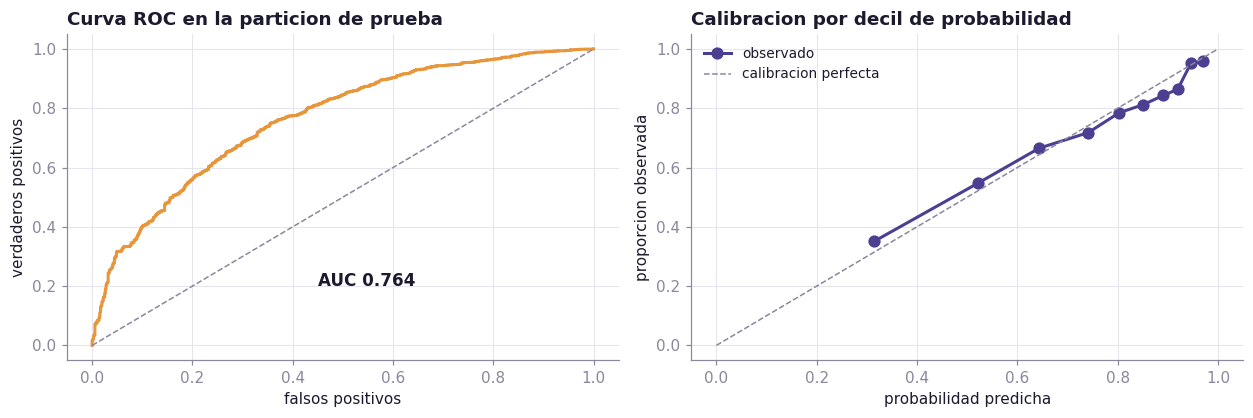

In [29]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.9))
fpr, tpr, _ = roc_curve(test["actividad_detectada"].astype(int), prob_test)
ejes[0].plot(fpr, tpr, color=ac.ACENTO, linewidth=2)
ejes[0].plot([0, 1], [0, 1], color=ac.GRIS, linewidth=1, linestyle="--")
ejes[0].set_title("Curva ROC en la particion de prueba")
ejes[0].set_xlabel("falsos positivos"); ejes[0].set_ylabel("verdaderos positivos")
ejes[0].text(0.45, 0.2, f"AUC {auc_test:.3f}", fontsize=11, color=ac.TINTA, fontweight="bold")

deciles = pd.qcut(prob_test, 10, labels=False, duplicates="drop")
observado = pd.Series(test["actividad_detectada"].astype(int).to_numpy()).groupby(deciles).mean()
predicho = pd.Series(prob_test).groupby(deciles).mean()
ejes[1].plot(predicho.values, observado.values, "o-", color=ac.MORADO, linewidth=2, markersize=7, label="observado")
ejes[1].plot([0, 1], [0, 1], color=ac.GRIS, linewidth=1, linestyle="--", label="calibracion perfecta")
ejes[1].set_title("Calibracion por decil de probabilidad")
ejes[1].set_xlabel("probabilidad predicha"); ejes[1].set_ylabel("proporcion observada")
ejes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 5.3 Etapa B — Ingreso por día de exposición

Todos los modelos reciben el mismo preprocesamiento, la misma partición y la misma validación
cruzada agrupada. El ajuste ocurre sobre el logaritmo del objetivo y la predicción se devuelve a
pesos, porque el logaritmo hace que el modelo trabaje con diferencias proporcionales y porque
impide que prediga ingresos negativos.

In [30]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor

activos = train[train["exposicion_observable"] & train["actividad_detectada"]].copy()
print(f"Muestra de la etapa B: {len(activos):,} anuncios de {activos['host_id'].nunique():,} anfitriones")

def modelo(estimador):                                        # Pipeline completo de un modelo
    base = Pipeline([("prep", ac.armar_preprocesador(ac.BLOQUES_ELEGIDOS)), ("modelo", estimador)])
    return TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)

MODELOS = {
    "Regresion lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=5000),
    "KNN (15 vecinos)": KNeighborsRegressor(n_neighbors=15),
    "Arbol (profundidad 8)": DecisionTreeRegressor(max_depth=8, random_state=ac.SEMILLA),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=ac.SEMILLA, n_jobs=-1),
    "Potenciado (histogramas)": HistGradientBoostingRegressor(random_state=ac.SEMILLA),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9,
                            colsample_bytree=0.9, random_state=ac.SEMILLA, n_jobs=-1, verbosity=0),
    "Red neuronal (64-32)": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=400,
                                         random_state=ac.SEMILLA, early_stopping=True),
}
METRICAS = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

def evaluar(nombre, estimador):
    t0 = time.time()
    r = cross_validate(estimador, activos, activos["ingreso_por_dia"], cv=cv,
                       groups=activos["host_id"], scoring=METRICAS)
    print(f"  {nombre:28s} listo en {time.time() - t0:5.1f} s", flush=True)
    return {"Modelo": nombre, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(),
            "R2": r["test_r2"].mean(), "desv R2": r["test_r2"].std(), "Tiempo (s)": time.time() - t0}

resultados = [evaluar("Linea base (mediana)", DummyRegressor(strategy="median")),
              evaluar("Regla a mano (localidad)", ac.ReglaPorGrupo("neighbourhood_cleansed"))]
for nombre, estimador in MODELOS.items():
    resultados.append(evaluar(nombre, modelo(estimador)))

etapa_b = pd.DataFrame(resultados).set_index("Modelo").sort_values("MAE")
print()
print(etapa_b.round(3).to_string())
ac.guardar(etapa_b, "etapa_b_modelos.csv")

Muestra de la etapa B: 9,586 anuncios de 3,784 anfitriones
  Linea base (mediana)         listo en   0.1 s


  Regla a mano (localidad)     listo en   0.1 s


  Regresion lineal             listo en   4.6 s


  Ridge                        listo en   3.9 s


  Lasso                        listo en   4.2 s


...

  Potenciado (histogramas)     listo en   6.2 s


  XGBoost                      listo en   7.2 s


  Red neuronal (64-32)         listo en  11.0 s



                                MAE        RMSE     R2  desv R2  Tiempo (s)
Modelo                                                                     
XGBoost                  42,876.555  92,062.163  0.121    0.043       7.234
Potenciado (histogramas) 42,983.589  92,492.537  0.113    0.033       6.167
Random forest            43,690.546  93,957.365  0.084    0.029      55.455
Lasso                    44,215.947  95,677.753  0.050    0.031       4.176
Ridge                    44,255.605  95,722.697  0.049    0.032       3.856
Regresion lineal         44,257.138  95,724.703  0.049    0.032       4.590
KNN (15 vecinos)         45,808.757  96,299.496  0.037    0.019       4.475
Arbol (profundidad 8)    48,594.835 104,162.828 -0.127    0.072       4.484
Regla a mano (localidad) 50,015.026 100,953.868 -0.061    0.025       0.064
Linea base (mediana)     50,343.352 101,717.132 -0.077    0.026       0.081
Red neuronal (64-32)            NaN         NaN    NaN      NaN      11.016


WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/etapa_b_modelos.csv')

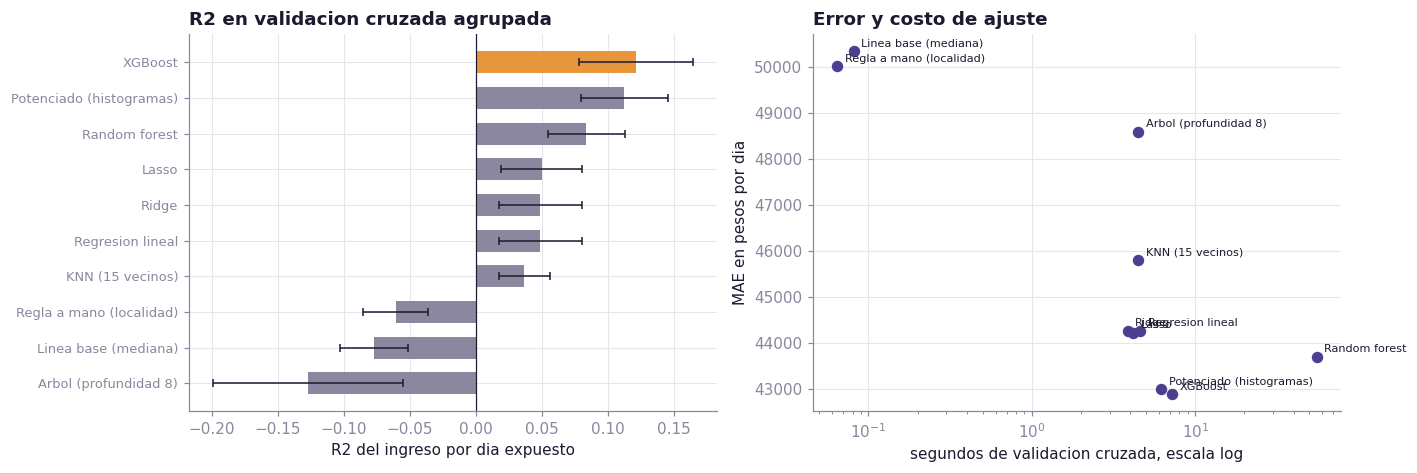

In [31]:
orden = etapa_b.sort_values("R2")
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
colores = [ac.ACENTO if n == etapa_b["R2"].idxmax() else ac.GRIS for n in orden.index]
ejes[0].barh(orden.index, orden["R2"], color=colores, height=0.62)
ejes[0].errorbar(orden["R2"], np.arange(len(orden)), xerr=orden["desv R2"],
                 fmt="none", ecolor=ac.TINTA, elinewidth=1, capsize=2.5)
ejes[0].axvline(0, color=ac.TINTA, linewidth=0.8)
ejes[0].set_title("R2 en validacion cruzada agrupada")
ejes[0].set_xlabel("R2 del ingreso por dia expuesto"); ejes[0].tick_params(axis="y", labelsize=8.5)

ejes[1].scatter(etapa_b["Tiempo (s)"], etapa_b["MAE"], s=42, color=ac.MORADO, zorder=3)
for nombre, fila in etapa_b.iterrows():
    ejes[1].annotate(nombre, (fila["Tiempo (s)"], fila["MAE"]), fontsize=7.4,
                     xytext=(5, 3), textcoords="offset points", color=ac.TINTA)
ejes[1].set_xscale("log")
ejes[1].set_title("Error y costo de ajuste")
ejes[1].set_xlabel("segundos de validacion cruzada, escala log"); ejes[1].set_ylabel("MAE en pesos por dia")
plt.tight_layout()
plt.show()

## 5.4 Dos formas de llegar al ingreso

El ingreso por día es el producto de la tarifa por la fracción de días vendidos, y los dos
factores están medidos con calidad distinta. La tarifa se lee de la fuente y existe para todos
los anuncios; la ocupación se infiere del recuento de comentarios. Estimar el producto de una
vez mezcla las dos calidades en un mismo residuo, mientras que estimar cada factor por separado
permite medir cuánto de la dificultad vive en cada uno.

Las predicciones de los dos factores se obtienen fuera de la partición de ajuste, de modo que el
producto se evalúe sobre estimaciones que ninguno de los dos modelos vio al entrenarse.

In [32]:
from sklearn.model_selection import cross_val_predict

activos["tasa_ocupacion"] = (activos["noches_ocupadas"] / activos["dias_expuesto"]).clip(0, 1)
finalista_b = etapa_b.drop(["Linea base (mediana)", "Regla a mano (localidad)"]).index[0]
print(f"Modelo de referencia para los tres ajustes: {finalista_b}")

pred_directo = cross_val_predict(modelo(MODELOS[finalista_b]), activos, activos["ingreso_por_dia"],
                                 cv=cv, groups=activos["host_id"])
pred_tarifa = cross_val_predict(modelo(MODELOS[finalista_b]), activos, activos["precio_noche"],
                                cv=cv, groups=activos["host_id"])
pred_ocupacion = cross_val_predict(modelo(MODELOS[finalista_b]), activos, activos["tasa_ocupacion"],
                                   cv=cv, groups=activos["host_id"])
producto = np.clip(pred_tarifa, 0, None) * np.clip(pred_ocupacion, 0, 1)

comparacion = pd.DataFrame({
    "Estimacion directa del ingreso": ac.metricas(activos["ingreso_por_dia"], pred_directo),
    "Producto de tarifa por ocupacion": ac.metricas(activos["ingreso_por_dia"], producto),
}).T
print()
print("Ingreso por dia expuesto, validacion cruzada agrupada:")
print(comparacion.to_string())

from sklearn.metrics import r2_score
r2_tarifa = r2_score(np.log1p(activos["precio_noche"]), np.log1p(np.clip(pred_tarifa, 0, None)))
r2_ocupacion = r2_score(np.log1p(activos["tasa_ocupacion"]), np.log1p(np.clip(pred_ocupacion, 0, 1)))
print()
print(f"R2 de cada factor por separado, en escala logaritmica:")
print(f"  tarifa por noche, que se lee de la fuente:        {r2_tarifa:.3f}")
print(f"  tasa de ocupacion, que se infiere de comentarios: {r2_ocupacion:.3f}")
print()
print("La distancia entre los dos factores no se cierra con un modelo mejor: procede de como")
print("esta construida cada cantidad.")
ac.guardar(comparacion, "comparacion_enfoques.csv")

Modelo de referencia para los tres ajustes: XGBoost



Ingreso por dia expuesto, validacion cruzada agrupada:
                                        MAE      MedAE       RMSE    R2
Estimacion directa del ingreso   42,876.354 23,211.326 92,475.010 0.116
Producto de tarifa por ocupacion 43,520.155 26,699.198 89,479.841 0.173

R2 de cada factor por separado, en escala logaritmica:
  tarifa por noche, que se lee de la fuente:        0.613
  tasa de ocupacion, que se infiere de comentarios: 0.138

La distancia entre los dos factores no se cierra con un modelo mejor: procede de como
esta construida cada cantidad.


WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/comparacion_enfoques.csv')

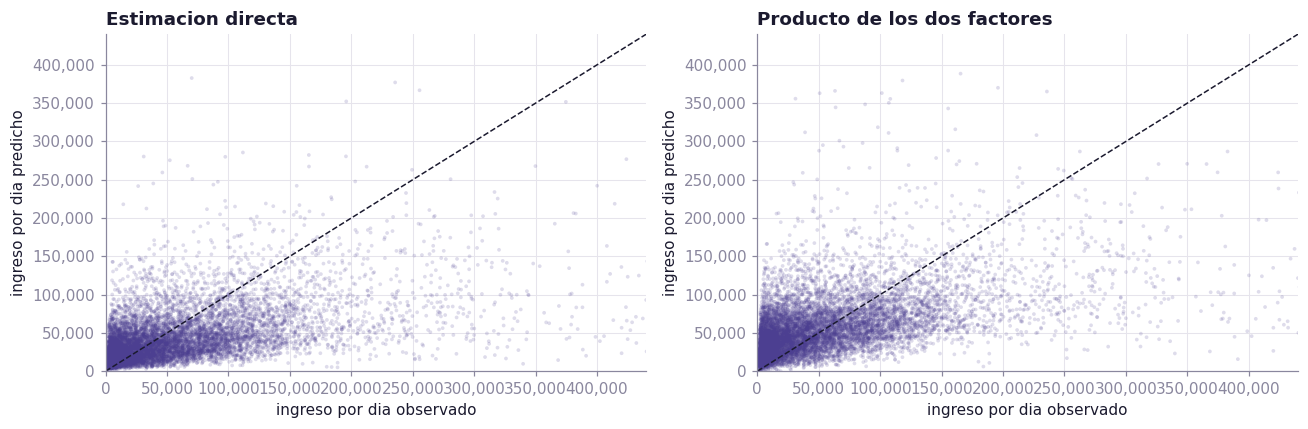

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
limite = float(np.percentile(activos["ingreso_por_dia"], 99))
for eje, pred, titulo in [(ejes[0], pred_directo, "Estimacion directa"),
                          (ejes[1], producto, "Producto de los dos factores")]:
    eje.scatter(activos["ingreso_por_dia"], pred, s=6, alpha=0.18, color=ac.MORADO, edgecolors="none")
    eje.plot([0, limite], [0, limite], color=ac.TINTA, linewidth=1, linestyle="--")
    eje.set_xlim(0, limite); eje.set_ylim(0, limite)
    eje.set_title(titulo)
    eje.set_xlabel("ingreso por dia observado"); eje.set_ylabel("ingreso por dia predicho")
    eje.xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
    eje.yaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
plt.tight_layout()
plt.show()

## 5.5 Lo que cuesta responderle a un propietario nuevo

In [34]:
escenarios = {}
for etiqueta, bloques in [("Propietario nuevo", ac.BLOQUES_ELEGIDOS),
                          ("Operador con historial", ac.BLOQUES_OPERADOR)]:
    r = cross_validate(Pipeline([("prep", ac.armar_preprocesador(bloques)),
                                 ("modelo", HistGradientBoostingRegressor(random_state=ac.SEMILLA))]),
                       activos, np.log1p(activos["ingreso_por_dia"]), cv=cv,
                       groups=activos["host_id"], scoring="r2")
    escenarios[etiqueta] = r["test_score"].mean()
    print(f"  {etiqueta:24s} R2 en escala logaritmica {r['test_score'].mean():.4f} (±{r['test_score'].std():.4f})", flush=True)
print()
print(f"Excluir las variables de desempeno cuesta "
      f"{escenarios['Operador con historial'] - escenarios['Propietario nuevo']:.4f} de R2. El distintivo de")
print("superanfitrion exige diez estancias completadas en la misma ventana que mide la actividad,")
print("de modo que para la primera etapa la variable implica la etiqueta.")

  Propietario nuevo        R2 en escala logaritmica 0.3027 (±0.0141)


  Operador con historial   R2 en escala logaritmica 0.3702 (±0.0134)



Excluir las variables de desempeno cuesta 0.0675 de R2. El distintivo de
superanfitrion exige diez estancias completadas en la misma ventana que mide la actividad,
de modo que para la primera etapa la variable implica la etiqueta.


## 5.6 Ajuste de los parámetros del finalista

In [35]:
from sklearn.model_selection import RandomizedSearchCV

REJILLAS = {
    "Random forest": ({"regressor__modelo__n_estimators": [300, 500],
                       "regressor__modelo__max_features": [0.2, 0.4, 0.7, 1.0],
                       "regressor__modelo__min_samples_leaf": [1, 2, 5, 10]},
                      RandomForestRegressor(random_state=ac.SEMILLA, n_jobs=-1)),
    "XGBoost": ({"regressor__modelo__n_estimators": [300, 500, 800],
                 "regressor__modelo__learning_rate": [0.03, 0.05, 0.08],
                 "regressor__modelo__max_depth": [4, 6, 8],
                 "regressor__modelo__subsample": [0.7, 0.9, 1.0]},
                XGBRegressor(random_state=ac.SEMILLA, n_jobs=-1, verbosity=0)),
}
rejilla, estimador_base = REJILLAS.get(finalista_b, (
    {"regressor__modelo__max_iter": [200, 400, 600],
     "regressor__modelo__learning_rate": [0.03, 0.05, 0.08, 0.12],
     "regressor__modelo__max_leaf_nodes": [15, 31, 63],
     "regressor__modelo__min_samples_leaf": [10, 20, 40]},
    HistGradientBoostingRegressor(random_state=ac.SEMILLA)))

t0 = time.time()
busqueda = RandomizedSearchCV(modelo(estimador_base), rejilla, n_iter=12, cv=GroupKFold(n_splits=3),
                              scoring="neg_mean_absolute_error", random_state=ac.SEMILLA, n_jobs=1)
busqueda.fit(activos, activos["ingreso_por_dia"], groups=activos["host_id"])
print(f"Combinaciones evaluadas: {len(busqueda.cv_results_['params'])} en {time.time() - t0:.0f} s")
print(f"MAE con parametros por defecto: ${etapa_b.loc[finalista_b, 'MAE']:,.0f} por dia")
print(f"MAE con parametros ajustados:   ${-busqueda.best_score_:,.0f} por dia")
print()
for clave, valor in busqueda.best_params_.items():
    print(f"  {clave.split('__')[-1]:20s} {valor}")

Combinaciones evaluadas: 12 en 57 s
MAE con parametros por defecto: $42,877 por dia
MAE con parametros ajustados:   $42,495 por dia

  subsample            0.9
  n_estimators         500
  max_depth            8
  learning_rate        0.03


---
# Paso 6 — Evaluación

**La última pregunta fue cuánto se puede mejorar, antes de seguir intentando.**

- Para responderla usamos los anuncios repetidos. Un mismo dueño publica a veces varios
  apartamentos en el mismo edificio, con la misma capacidad, el mismo número de habitaciones y
  en la misma localidad.
- Para el modelo esos anuncios son idénticos, porque todo lo que él ve es igual. Entonces lo que
  difiera entre ellos no lo puede explicar ningún modelo construido con estas variables, y esa
  diferencia mide el techo.
- Entre esos pares, las noches vendidas se diferencian a la mitad. Dos apartamentos iguales, uno
  al lado del otro, rinden muy distinto por razones que el archivo no registra: el piso, la
  vista, las fotos, o simplemente cómo atiende el dueño cada anuncio.

## 6.1 Medida final sobre la partición de prueba

La partición de prueba se usa una sola vez, con las dos etapas ya elegidas y ajustadas.

In [36]:
modelo_b = busqueda.best_estimator_
prediccion = prob_test * np.clip(modelo_b.predict(test), 0, None) * 365

evaluable = test["ingreso_anual"].notna()
y_test = test.loc[evaluable, "ingreso_anual"]
final = pd.DataFrame({
    "Linea base": ac.metricas(y_test, base.predict(test[evaluable])),
    "Regla a mano": ac.metricas(y_test, regla.predict(test[evaluable])),
    "Diseno en dos etapas": ac.metricas(y_test, prediccion[evaluable.to_numpy()]),
}).T
print(final.to_string())
mejora = (1 - final.loc["Diseno en dos etapas", "MAE"] / final.loc["Regla a mano", "MAE"]) * 100
mejora_med = (1 - final.loc["Diseno en dos etapas", "MedAE"] / final.loc["Regla a mano", "MedAE"]) * 100
print()
print(f"Reduccion del error absoluto medio frente a la regla a mano: {mejora:5.1f} %")
print(f"Reduccion de la mediana del error absoluto:                  {mejora_med:5.1f} %")
print()
print("La media del error la domina un grupo pequeno de alojamientos censurados en el techo de la")
print("estimacion, de modo que la mediana describe mejor el caso tipico.")
ac.guardar(final, "evaluacion_final.csv")

                                MAE         MedAE           RMSE     R2
Linea base           11,326,087.982 4,998,000.000 20,674,716.462 -0.148
Regla a mano         11,256,048.697 4,859,808.000 20,567,835.529 -0.136
Diseno en dos etapas  9,676,697.691 5,782,545.215 16,395,297.288  0.278

Reduccion del error absoluto medio frente a la regla a mano:  14.0 %
Reduccion de la mediana del error absoluto:                  -19.0 %

La media del error la domina un grupo pequeno de alojamientos censurados en el techo de la
estimacion, de modo que la mediana describe mejor el caso tipico.


WindowsPath('C:/Users/USUARIO/Music/ML_Maestria/proyecto-airbnb/notebooks/salidas/evaluacion_final.csv')

## 6.2 Importancia por permutación

La importancia por permutación mide cuánto empeora el error al desordenar una sola columna, de
modo que recoge el aporte de la variable al modelo ya ajustado y permite contrastarlo con el
signo declarado en el paso cuatro.

amenities             26,204.500
latitude              14,611.600
longitude             13,283.100
accommodates          12,363.400
bedrooms               8,130.800
name                   7,582.900
room_type              7,521.900
bathrooms_text         5,863.900
beds                   5,717.300
minimum_nights         5,529.300
description            5,215.000
host_listings_count    5,028.100


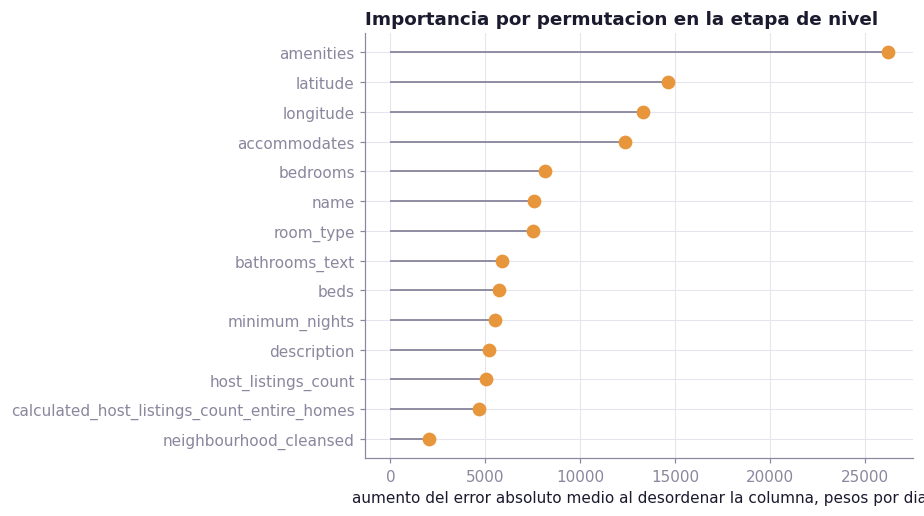

In [37]:
from sklearn.inspection import permutation_importance

muestra = activos.sample(min(1200, len(activos)), random_state=ac.SEMILLA)
importancia = permutation_importance(modelo_b, muestra, muestra["ingreso_por_dia"],
                                     n_repeats=5, random_state=ac.SEMILLA,
                                     scoring="neg_mean_absolute_error")
pesos = pd.Series(importancia.importances_mean, index=muestra.columns)
pesos = pesos[pesos > 0].sort_values(ascending=False)
print(pesos.head(12).round(1).to_string())

top = pesos.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hlines(top.index, 0, top.values, color=ac.GRIS, linewidth=1.2)
ax.plot(top.values, top.index, "o", color=ac.ACENTO, markersize=8)
ax.set_title("Importancia por permutacion en la etapa de nivel")
ax.set_xlabel("aumento del error absoluto medio al desordenar la columna, pesos por dia")
plt.tight_layout()
plt.show()

## 6.3 Dónde se equivoca el modelo

In [38]:
errores = pd.DataFrame({
    "real": y_test.to_numpy(), "predicho": prediccion[evaluable.to_numpy()],
    "room_type": test.loc[evaluable, "room_type"].to_numpy(),
    "noches": test.loc[evaluable, "noches_ocupadas"].to_numpy(),
}, index=y_test.index)
errores["error_abs"] = (errores["real"] - errores["predicho"]).abs()
errores["estado"] = np.where(errores["noches"] == 0, "Sin actividad",
                      np.where(errores["noches"] >= 255, "En el tope", "Con actividad"))

por_estado = errores.groupby("estado").agg(
    alojamientos=("real", "size"), ingreso_mediano=("real", "median"),
    prediccion_mediana=("predicho", "median"), MAE=("error_abs", "mean"), MedAE=("error_abs", "median"))
print("Error por estado del anuncio:")
print(por_estado.round(0).to_string())
print()
print("Error por tipo de alojamiento:")
print(errores.groupby("room_type").agg(alojamientos=("real", "size"), ingreso_mediano=("real", "median"),
      MedAE=("error_abs", "median")).sort_values("alojamientos", ascending=False).round(0).to_string())

Error por estado del anuncio:
               alojamientos  ingreso_mediano  prediccion_mediana            MAE          MedAE
estado                                                                                        
Con actividad          1948    7,749,000.000      10,154,043.000  9,205,537.000  5,648,371.000
En el tope              205   38,785,500.000      14,987,116.000 25,131,681.000 20,335,253.000
Sin actividad           720            0.000       4,014,902.000  6,551,071.000  4,014,902.000

Error por tipo de alojamiento:
                 alojamientos  ingreso_mediano         MedAE
room_type                                                   
Entire home/apt          2017    8,280,000.000 8,414,929.000
Private room              812    1,011,127.000 2,374,435.000
Shared room                41    1,156,104.000 1,478,215.000
Hotel room                  3            0.000   660,524.000


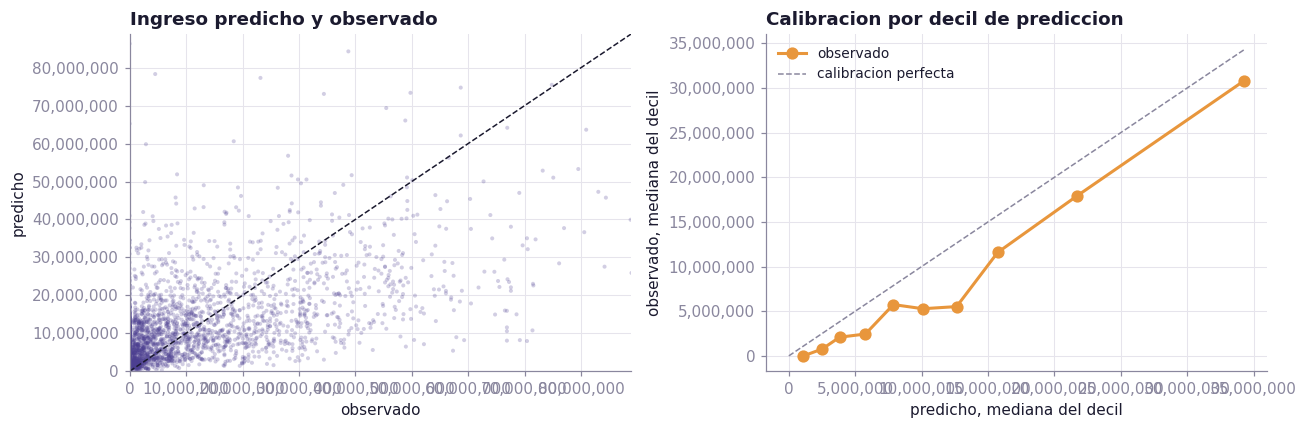

In [39]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
limite = float(np.percentile(errores["real"], 99))
ejes[0].scatter(errores["real"], errores["predicho"], s=7, alpha=0.25, color=ac.MORADO, edgecolors="none")
ejes[0].plot([0, limite], [0, limite], color=ac.TINTA, linewidth=1, linestyle="--")
ejes[0].set_xlim(0, limite); ejes[0].set_ylim(0, limite)
ejes[0].set_title("Ingreso predicho y observado")
ejes[0].set_xlabel("observado"); ejes[0].set_ylabel("predicho")
ejes[0].xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[0].yaxis.set_major_formatter(plt.FuncFormatter(ac.miles))

decil = pd.qcut(errores["predicho"], 10, labels=False, duplicates="drop")
calibracion = errores.groupby(decil).agg(observado=("real", "median"), predicho=("predicho", "median"))
ejes[1].plot(calibracion["predicho"], calibracion["observado"], "o-", color=ac.ACENTO, linewidth=2, markersize=7, label="observado")
tope_cal = calibracion.max().max()
ejes[1].plot([0, tope_cal], [0, tope_cal], color=ac.GRIS, linewidth=1, linestyle="--", label="calibracion perfecta")
ejes[1].set_title("Calibracion por decil de prediccion")
ejes[1].set_xlabel("predicho, mediana del decil"); ejes[1].set_ylabel("observado, mediana del decil")
ejes[1].xaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[1].yaxis.set_major_formatter(plt.FuncFormatter(ac.miles))
ejes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 6.4 El techo de lo predecible

Dos anuncios del mismo anfitrión con igual tipo, capacidad, número de habitaciones y localidad
comparten todo lo que el modelo observa. La diferencia de ingreso entre ellos es, para este
conjunto de variables, inexplicable, y la proporción de varianza que sobrevive dentro de los
grupos de gemelos marca el techo de cualquier modelo construido con ellas.

Anuncios con al menos un gemelo: 7,152 de 12,766 en 1,786 grupos

Techo estimado, con el objetivo en escala logaritmica:
  tarifa por noche                   n= 7,152   techo de R2 ~ 0.868


  ingreso anual                      n= 7,152   techo de R2 ~ 0.484


  ingreso por dia, solo activos      n= 5,198   techo de R2 ~ 0.616

Entre gemelos activos, la desviacion mediana de las noches ocupadas es de 27 noches sobre una media mediana de 62,
un coeficiente de variacion del 50 %.


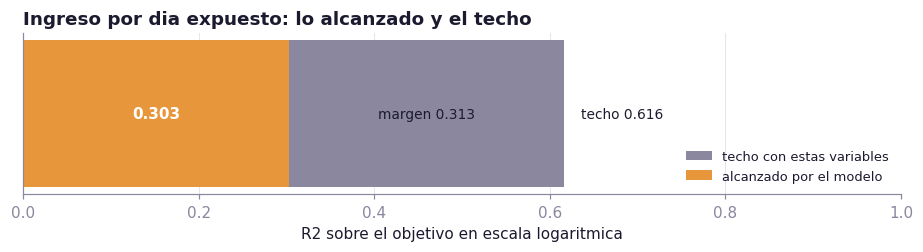

In [40]:
LLAVE = ["host_id", "room_type", "accommodates", "bedrooms", "neighbourhood_cleansed"]
train["grupo_gemelos"] = train.groupby(LLAVE, dropna=False).ngroup()
gemelos = train[train["grupo_gemelos"].map(train["grupo_gemelos"].value_counts()) >= 2]
print(f"Anuncios con al menos un gemelo: {len(gemelos):,} de {len(train):,} en {gemelos['grupo_gemelos'].nunique():,} grupos")

def techo_r2(tabla, columna, etiqueta):
    t = tabla[tabla[columna].notna()]
    t = t[t.groupby("grupo_gemelos")[columna].transform("size") >= 2]
    y = np.log1p(t[columna])
    dentro = (y.groupby(t["grupo_gemelos"]).transform(lambda s: s - s.mean()).pow(2).sum()
              / (len(y) - t["grupo_gemelos"].nunique()))
    techo = 1 - dentro / y.var(ddof=1)
    print(f"  {etiqueta:34s} n={len(y):6,d}   techo de R2 ~ {techo:.3f}")
    return techo

print()
print("Techo estimado, con el objetivo en escala logaritmica:")
techo_r2(gemelos, "precio_noche", "tarifa por noche")
techo_r2(gemelos, "ingreso_anual", "ingreso anual")
activos_gemelos = gemelos[gemelos["exposicion_observable"] & gemelos["actividad_detectada"]]
techo_tasa = techo_r2(activos_gemelos, "ingreso_por_dia", "ingreso por dia, solo activos")

dispersion = activos_gemelos.groupby("grupo_gemelos")["noches_ocupadas"].agg(["mean", "std", "size"])
dispersion = dispersion[dispersion["size"] >= 2]
print()
print(f"Entre gemelos activos, la desviacion mediana de las noches ocupadas es de "
      f"{dispersion['std'].median():.0f} noches sobre una media mediana de {dispersion['mean'].median():.0f},")
print(f"un coeficiente de variacion del {(dispersion['std'] / dispersion['mean']).median() * 100:.0f} %.")

alcanzado = escenarios["Propietario nuevo"]
fig, ax = plt.subplots(figsize=(8.5, 2.4))
ax.barh([0], [techo_tasa], color=ac.GRIS, height=0.42, label="techo con estas variables")
ax.barh([0], [alcanzado], color=ac.ACENTO, height=0.42, label="alcanzado por el modelo")
ax.set_yticks([]); ax.set_xlim(0, 1)
ax.set_title("Ingreso por dia expuesto: lo alcanzado y el techo")
ax.set_xlabel("R2 sobre el objetivo en escala logaritmica")
ax.text(alcanzado / 2, 0, f"{alcanzado:.3f}", ha="center", va="center", color="white", fontweight="bold")
ax.text((alcanzado + techo_tasa) / 2, 0, f"margen {techo_tasa - alcanzado:.3f}", ha="center", va="center",
        fontsize=9, color=ac.TINTA)
ax.text(techo_tasa + 0.02, 0, f"techo {techo_tasa:.3f}", va="center", fontsize=9, color=ac.TINTA)
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

Una parte grande de la variación del ingreso no está en ninguna columna de la fuente, y buena
parte de esa parte no está en el fenómeno: procede de estimar la ocupación a partir del recuento
de comentarios de cada alojamiento. El techo corresponde a este conjunto de variables y no a un
límite del problema; información genuinamente nueva, como las fotografías del anuncio o el
tiempo de respuesta del anfitrión, lo desplazaría hacia arriba.

## 6.5 Respuesta a la pregunta de investigación

In [41]:
print("PREGUNTA 3. Dadas las caracteristicas de una vivienda, cual puede ser su rentabilidad anual.")
print("=" * 98)
print()
print(f"Sobre la particion de prueba, con anfitriones que el modelo no vio, el diseno predice el")
print(f"ingreso bruto anual con una mediana de error absoluto de ${final.loc['Diseno en dos etapas', 'MedAE']:,.0f}")
print(f"y un error absoluto medio de ${final.loc['Diseno en dos etapas', 'MAE']:,.0f}, sobre un ingreso mediano observado de")
print(f"${y_test.median():,.0f}. La regla a mano se equivoca en ${final.loc['Regla a mano', 'MedAE']:,.0f} de mediana.")
print()
print(f"La etapa de riesgo separa los anuncios que llegan a registrar actividad con un AUC de {auc_test:.3f}.")
print(f"La etapa de nivel alcanza un R2 de {alcanzado:.3f} frente a un techo estimado de {techo_tasa:.3f}.")
print()
print("Error segun el estado del anuncio:")
for estado, fila in por_estado.iterrows():
    print(f"  {estado:16s} {int(fila['alojamientos']):5d} anuncios   "
          f"observado ${fila['ingreso_mediano']:>13,.0f}   mediana del error ${fila['MedAE']:>13,.0f}")
print()
print("Variables de mayor aporte:")
for nombre, valor in pesos.head(6).items():
    print(f"  {nombre:42s} {valor:>10,.0f} pesos por dia")

PREGUNTA 3. Dadas las caracteristicas de una vivienda, cual puede ser su rentabilidad anual.

Sobre la particion de prueba, con anfitriones que el modelo no vio, el diseno predice el
ingreso bruto anual con una mediana de error absoluto de $5,782,545
y un error absoluto medio de $9,676,698, sobre un ingreso mediano observado de
$4,817,664. La regla a mano se equivoca en $4,859,808 de mediana.

La etapa de riesgo separa los anuncios que llegan a registrar actividad con un AUC de 0.764.
La etapa de nivel alcanza un R2 de 0.303 frente a un techo estimado de 0.616.

Error segun el estado del anuncio:
  Con actividad     1948 anuncios   observado $    7,749,000   mediana del error $    5,648,371
  En el tope         205 anuncios   observado $   38,785,500   mediana del error $   20,335,253
  Sin actividad      720 anuncios   observado $            0   mediana del error $    4,014,902

Variables de mayor aporte:
  amenities                                      26,204 pesos por dia
  latitude

# Conclusiones

El ingreso anual de un alojamiento resulta predecible a partir de características conocidas antes
de operar, con una precisión que depende del segmento y que es menor de lo que sugiere una
validación aleatoria. La predicción distingue con holgura un apartamento completo céntrico de una
habitación compartida periférica, y pierde capacidad en los dos extremos de la distribución.

La separación entre riesgo y nivel recupera la capacidad predictiva que una regresión única
pierde al promediar poblaciones con comportamiento distinto, y entrega dos cifras que el
propietario necesita por separado. La primera es con qué probabilidad su alojamiento consigue
venderse, y la segunda cuánto rinde si lo consigue.

Los dos factores del ingreso no ofrecen la misma dificultad. La tarifa responde a atributos
observables del inmueble, mientras que la ocupación depende de decisiones de gestión y de la
posición en el buscador, que las características estáticas recogen de forma indirecta.

El margen de mejora está acotado por la medición y no por el modelo. El objetivo se construye
contando comentarios, y entre alojamientos idénticos en todo lo observable las noches vendidas
difieren a la mitad.

**Limitaciones.** El objetivo es una estimación de la fuente y no un ingreso contable; hereda el
supuesto de tasa de reseña con que se construye y su techo censura a los más activos. El cero no
distingue al anuncio nuevo del abandonado, porque el archivo no trae la fecha de publicación. El
régimen de tarifa mensual queda fuera por estar mal medido en los dos factores. La medida es de
ingreso bruto, de modo que compararla con el arriendo tradicional exigiría descontar la
operación, el aseo, los servicios y la vacancia, además de un precio de referencia del arriendo
residencial que la fuente no contiene. Los datos corresponden a una sola extracción, por lo que
no permiten separar la temporada de la anticipación de la reserva.